FUNCTION PLAN for IF-MACTOR Flood Risk Management Tool
════════════════════════════════════════════════════════

CORE MATH FUNCTIONS (4):
  1. aggregate_ifs_experts()      → Aggregates multiple experts using IFWG operator (Eq. 4)
  2. defuzzify_ifs()              → Converts IFS tuple (μ,ν) to crisp score (Eq. 5)
  3. build_mdi_matrix()           → Builds the defuzzified Direct Influence Matrix
  4. compute_mdii()               → Computes MDII = Direct + Indirect via min-rule (Eq. 6)

POWER CALCULATION FUNCTIONS (3):
  5. compute_influence_dependence() → Computes Iᵢ, Dᵢ from MDII (Eq. 7-8)
  6. compute_balance_of_power()     → Computes rᵢ and rᵢ* (Eq. 9-10)
  7. categorize_stakeholders()      → Classifies into 4 quadrants (Influential/Leading/Dependent/Autonomous)

GOAL ANALYSIS FUNCTIONS (3):
  8. build_stakeholder_goal_matrix() → Builds the aggregated MSG matrix (Table H)
  9. compute_mobilization()          → Computes Mᵢ for goals (Eq. 12)
  10. compute_wmsg()                 → Weighted Matrix of Stakeholders & Goals (Eq. 11)

VISUALIZATION FUNCTIONS (5):
  11. plot_power_histogram()         → Histogram of rᵢ* (like Fig. 5)
  12. plot_stakeholder_map()         → 2D influence-dependence quadrant map (like Fig. 6)
  13. plot_radar_charts()            → Radar charts for each stakeholder (like Fig. 7)
  14. plot_mobilization_bars()       → Bar chart of goal mobilization coefficients
  15. plot_knowledge_graph()         → NetworkX-based relational diagram

OUTPUT/REPORTING FUNCTIONS (2):
  16. build_results_tables()         → Returns pandas DataFrames for all results
  17. save_all_figures()             → Saves all PNGs to /content/if_mactor_outputs/

MASTER FUNCTION (1):
  18. run_workflow()                 → Takes all inputs, calls all above, saves outputs, displays results

TOTAL: 18 FUNCTIONS
════════════════════════════════════════════════════════

In [3]:
!pip install -q pandas numpy matplotlib networkx scikit-learn

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
from math import prod
import os
import warnings
warnings.filterwarnings('ignore')

# ═══════════════════════════════════════════════════════════════════
# SECTION A: CONSTANTS & MAPPINGS (Table 1 from the paper)
# ═══════════════════════════════════════════════════════════════════

# Linguistic term → IFS tuple (μ, ν)
IFS_MAP = {
    'AL': (0.05, 0.85),   # Absolutely Low
    'VL': (0.15, 0.75),   # Very Low
    'L':  (0.25, 0.65),   # Low
    'ML': (0.35, 0.55),   # Medium Low
    'AE': (0.45, 0.45),   # Almost Equal
    'MH': (0.55, 0.35),   # Medium High
    'H':  (0.65, 0.25),   # High
    'VH': (0.75, 0.15),   # Very High
    'AH': (0.85, 0.05),   # Absolutely High
}

# Quadrant labels based on (I, D) values
QUADRANTS = {
    'influential': ('High Influence', 'Low Dependence'),
    'leading':     ('High Influence', 'High Dependence'),
    'dependent':   ('Low Influence',  'High Dependence'),
    'autonomous':  ('Low Influence',  'Low Dependence'),
}

OUTPUT_DIR = '/content/if_mactor_outputs'
print("✅ Dependencies loaded. IFS_MAP has", len(IFS_MAP), "linguistic terms.")

✅ Dependencies loaded. IFS_MAP has 9 linguistic terms.


In [12]:
# ═══════════════════════════════════════════════════════════════════
# FUNCTION 1: Aggregate multiple experts using IFWG operator (Eq. 4)
# ═══════════════════════════════════════════════════════════════════
def aggregate_ifs_experts(linguistic_values, weights=None):
    n = len(linguistic_values)
    if weights is None:
        weights = [1.0 / n] * n
    assert abs(sum(weights) - 1.0) < 1e-6, "Weights must sum to 1"

    ifs_tuples = [IFS_MAP[term] for term in linguistic_values]
    mus = [t[0] for t in ifs_tuples]
    nus = [t[1] for t in ifs_tuples]

    mu_agg = prod([m ** w for m, w in zip(mus, weights)])
    nu_agg = 1.0 - prod([((1 - v) ** w) for v, w in zip(nus, weights)])
    return (round(mu_agg, 4), round(nu_agg, 4))


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 2: Defuzzify IFS tuple → crisp score (Eq. 5)
# ═══════════════════════════════════════════════════════════════════
def defuzzify_ifs(ifs_tuple):
    mu, nu = ifs_tuple
    return round(mu - nu, 4)


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 3: Build the defuzzified MDI (Direct Influence) Matrix
# ═══════════════════════════════════════════════════════════════════
def build_mdi_matrix(expert_surveys, stakeholders, weights=None):
    expert_ids = list(expert_surveys.keys())
    if weights is None:
        weights = {eid: 1.0 / len(expert_ids) for eid in expert_ids}

    # Initialize as numeric float — NOT object
    mdi = pd.DataFrame(0.0, index=stakeholders, columns=stakeholders, dtype=float)

    for i, si in enumerate(stakeholders):
        for j, sj in enumerate(stakeholders):
            if i == j:
                mdi.loc[si, sj] = 0.0
                continue
            words = [expert_surveys[eid][si][sj] for eid in expert_ids]
            wts = [weights[eid] for eid in expert_ids]
            agg_ifs = aggregate_ifs_experts(words, wts)
            mdi.loc[si, sj] = float(defuzzify_ifs(agg_ifs))
    return mdi


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 4: Compute MDII = Direct + Indirect (Eq. 6)
# ═══════════════════════════════════════════════════════════════════
def compute_mdii(mdi_df):
    stakeholders = list(mdi_df.index)
    mdii = mdi_df.copy().astype(float)

    for i, si in enumerate(stakeholders):
        for j, sj in enumerate(stakeholders):
            if i == j:
                mdii.loc[si, sj] = 0.0
                continue
            indirect = 0.0
            for k, sk in enumerate(stakeholders):
                if k == i or k == j:
                    continue
                indirect += min(float(mdi_df.loc[si, sk]), float(mdi_df.loc[sk, sj]))
            mdii.loc[si, sj] = round(float(mdi_df.loc[si, sj]) + indirect, 4)
    return mdii

In [13]:
# ═══════════════════════════════════════════════════════════════════
# FUNCTION 5: Influence (Iᵢ) and Dependence (Dᵢ)
# ═══════════════════════════════════════════════════════════════════
def compute_influence_dependence(mdii_df):
    stakeholders = list(mdii_df.index)
    I = {}
    D = {}
    for s in stakeholders:
        # Row sum minus own diagonal
        row_sum = float(mdii_df.loc[s].sum()) - float(mdii_df.loc[s, s])
        col_sum = float(mdii_df[s].sum()) - float(mdii_df.loc[s, s])
        I[s] = round(row_sum, 4)
        D[s] = round(col_sum, 4)
    return I, D


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 6: Balance of Power (rᵢ) and Coefficient (rᵢ*)
# ═══════════════════════════════════════════════════════════════════
def compute_balance_of_power(I, D, mdii_df):
    stakeholders = list(I.keys())
    sum_I = sum(I.values())

    r = {}
    for s in stakeholders:
        diag = float(mdii_df.loc[s, s])
        denom_I = (I[s] + D[s])
        partA = (I[s] - diag) / sum_I if sum_I > 0 else 0.0
        partB = I[s] / denom_I if denom_I > 0 else 0.0
        r[s] = round(partA * partB, 6)

    # Guard against all-zero r values
    r_avg = np.mean(list(r.values()))
    if r_avg == 0:
        r_avg = 1e-9   # avoid div-by-zero

    r_star = {s: round(r[s] / r_avg, 4) for s in stakeholders}

    df = pd.DataFrame({
        'Iᵢ (Influence)': [I[s] for s in stakeholders],
        'Dᵢ (Dependence)': [D[s] for s in stakeholders],
        'rᵢ (Raw Power)': [r[s] for s in stakeholders],
        'rᵢ* (Coefficient)': [r_star[s] for s in stakeholders],
    }, index=stakeholders)

    # ✅ FIX: rank then fillna BEFORE astype(int)
    ranks = df['rᵢ* (Coefficient)'].rank(ascending=False, method='min').fillna(len(df)).astype(int)
    df['Rank'] = ranks
    df = df.sort_values('Rank')
    return df, r


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 7: Categorize into 4 quadrants
# ═══════════════════════════════════════════════════════════════════
def categorize_stakeholders(power_df):
    med_I = power_df['Iᵢ (Influence)'].median()
    med_D = power_df['Dᵢ (Dependence)'].median()

    categories = {}
    for s in power_df.index:
        Iv = power_df.loc[s, 'Iᵢ (Influence)']
        Dv = power_df.loc[s, 'Dᵢ (Dependence)']
        if Iv >= med_I and Dv < med_D:
            categories[s] = 'Influential'
        elif Iv >= med_I and Dv >= med_D:
            categories[s] = 'Leading'
        elif Iv < med_I and Dv >= med_D:
            categories[s] = 'Dependent'
        else:
            categories[s] = 'Autonomous'
    return categories, med_I, med_D

In [14]:
# ═══════════════════════════════════════════════════════════════════
# FUNCTION 8: Build aggregated Stakeholder-Goal Matrix (MSG)
# ═══════════════════════════════════════════════════════════════════
def build_stakeholder_goal_matrix(goal_surveys, stakeholders, goals, weights=None):
    expert_ids = list(goal_surveys.keys())
    if weights is None:
        weights = {eid: 1.0 / len(expert_ids) for eid in expert_ids}

    msg = pd.DataFrame(0.0, index=stakeholders, columns=goals, dtype=float)

    for si in stakeholders:
        for gj in goals:
            words = [goal_surveys[eid][si][gj] for eid in expert_ids]
            wts = [weights[eid] for eid in expert_ids]
            agg_ifs = aggregate_ifs_experts(words, wts)
            msg.loc[si, gj] = float(defuzzify_ifs(agg_ifs))
    return msg


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 9: Weighted MSG (Eq. 11)
# ═══════════════════════════════════════════════════════════════════
def compute_wmsg(msg_df, r_dict):
    wmsg = msg_df.copy().astype(float)
    for s in msg_df.index:
        wmsg.loc[s] = msg_df.loc[s] * r_dict[s]
    return wmsg.round(4)


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 10: Mobilization Coefficient (Mᵢ) (Eq. 12)
# ═══════════════════════════════════════════════════════════════════
def compute_mobilization(wmsg_df):
    mobil = wmsg_df.sum(axis=0).round(4)

    # ✅ FIX: fillna before astype(int)
    ranks = mobil.rank(ascending=False, method='min').fillna(len(mobil)).astype(int)

    df = pd.DataFrame({'Mᵢ (Mobilization)': mobil, 'Rank': ranks})
    return df.sort_values('Rank')

In [8]:
# ═══════════════════════════════════════════════════════════════════
# FUNCTION 11: Power Histogram (like Fig. 5)
# ═══════════════════════════════════════════════════════════════════
def plot_power_histogram(power_df, save_path=None):
    fig, ax = plt.subplots(figsize=(10, 5))
    colors = ['#ff6b6b' if v > 1 else '#54a0ff' for v in power_df['rᵢ* (Coefficient)']]
    bars = ax.bar(power_df.index, power_df['rᵢ* (Coefficient)'], color=colors, edgecolor='black')
    ax.axhline(y=1.0, color='red', linestyle='--', linewidth=2, label='Average Power (1.0)')
    ax.set_title('Balance of Power Coefficient (rᵢ*)', fontsize=14, fontweight='bold')
    ax.set_xlabel('Stakeholder'); ax.set_ylabel('rᵢ*')
    ax.legend()
    for bar, val in zip(bars, power_df['rᵢ* (Coefficient)']):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f'{val:.2f}', ha='center', fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 12: Stakeholder Map (like Fig. 6)
# ═══════════════════════════════════════════════════════════════════
def plot_stakeholder_map(power_df, categories, med_I, med_D, save_path=None):
    fig, ax = plt.subplots(figsize=(10, 8))
    color_map = {'Influential': '#ff6b6b', 'Leading': '#feca57',
                 'Dependent': '#54a0ff', 'Autonomous': '#1dd1a1'}

    for s in power_df.index:
        x = power_df.loc[s, 'Dᵢ (Dependence)']
        y = power_df.loc[s, 'Iᵢ (Influence)']
        cat = categories[s]
        ax.scatter(x, y, s=400, color=color_map[cat], edgecolor='black', linewidth=2, zorder=3)
        ax.annotate(s, (x, y), ha='center', va='center', fontsize=9, fontweight='bold', zorder=4)

    ax.axhline(y=med_I, color='gray', linestyle='--', alpha=0.5)
    ax.axvline(x=med_D, color='gray', linestyle='--', alpha=0.5)

    # Quadrant labels
    xlim = ax.get_xlim(); ylim = ax.get_ylim()
    ax.text(xlim[0] + 0.02*(xlim[1]-xlim[0]), ylim[1] - 0.03*(ylim[1]-ylim[0]),
            'INFLUENTIAL', fontsize=10, fontweight='bold', color='#c0392b')
    ax.text(xlim[1] - 0.20*(xlim[1]-xlim[0]), ylim[1] - 0.03*(ylim[1]-ylim[0]),
            'LEADING', fontsize=10, fontweight='bold', color='#d35400')
    ax.text(xlim[1] - 0.20*(xlim[1]-xlim[0]), ylim[0] + 0.03*(ylim[1]-ylim[0]),
            'DEPENDENT', fontsize=10, fontweight='bold', color='#2e86de')
    ax.text(xlim[0] + 0.02*(xlim[1]-xlim[0]), ylim[0] + 0.03*(ylim[1]-ylim[0]),
            'AUTONOMOUS', fontsize=10, fontweight='bold', color='#10ac84')

    ax.set_xlabel('Dependence (Dᵢ)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Influence (Iᵢ)', fontsize=12, fontweight='bold')
    ax.set_title('Stakeholder Influence-Dependence Map', fontsize=14, fontweight='bold')

    legend_handles = [mpatches.Patch(color=c, label=l) for l, c in color_map.items()]
    ax.legend(handles=legend_handles, loc='best')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 13: Radar Charts for each stakeholder (like Fig. 7)
# ═══════════════════════════════════════════════════════════════════
def plot_radar_charts(msg_df, save_path=None):
    from math import pi
    stakeholders = list(msg_df.index)
    goals = list(msg_df.columns)
    angles = [n / len(goals) * 2 * pi for n in range(len(goals))]
    angles += angles[:1]

    fig, axes = plt.subplots(1, len(stakeholders), figsize=(4*len(stakeholders), 4.5),
                              subplot_kw=dict(polar=True))
    if len(stakeholders) == 1:
        axes = [axes]

    for ax, s in zip(axes, stakeholders):
        values = msg_df.loc[s].tolist()
        values += values[:1]
        ax.plot(angles, values, color='#c0392b', linewidth=2)
        ax.fill(angles, values, color='#c0392b', alpha=0.25)
        ax.set_xticks(angles[:-1])
        ax.set_xticklabels(goals, fontsize=8)
        ax.set_ylim(0, 1)
        ax.set_title(s, fontweight='bold', pad=10)

    plt.suptitle('Stakeholder → Goal Priority Radar Charts', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 14: Mobilization bar chart
# ═══════════════════════════════════════════════════════════════════
def plot_mobilization_bars(mobil_df, save_path=None):
    fig, ax = plt.subplots(figsize=(9, 5))
    colors = ['#10ac84' if i == 0 else '#feca57' if i == 1 else '#e67e22'
              for i in range(len(mobil_df))]
    bars = ax.barh(mobil_df.index, mobil_df['Mᵢ (Mobilization)'], color=colors, edgecolor='black')
    ax.set_xlabel('Mobilization Coefficient (Mᵢ)', fontsize=12, fontweight='bold')
    ax.set_title('Goal Mobilization Ranking (Weighted by Power)', fontsize=14, fontweight='bold')
    ax.invert_yaxis()
    for bar, val in zip(bars, mobil_df['Mᵢ (Mobilization)']):
        ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                f'{val:.2f}', va='center', fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 15: Knowledge Graph (NetworkX relational diagram)
# ═══════════════════════════════════════════════════════════════════
def plot_knowledge_graph(mdii_df, msg_df, power_df, categories, save_path=None):
    fig, ax = plt.subplots(figsize=(16, 12))
    G = nx.DiGraph()

    color_map = {'Influential': '#ff6b6b', 'Leading': '#feca57',
                 'Dependent': '#54a0ff', 'Autonomous': '#1dd1a1'}

    # Stakeholder nodes
    for s in mdii_df.index:
        G.add_node(s, kind='stakeholder', category=categories[s],
                   influence=power_df.loc[s, 'Iᵢ (Influence)'],
                   dependence=power_df.loc[s, 'Dᵢ (Dependence)'])
    # Goal nodes
    for g in msg_df.columns:
        G.add_node(g, kind='goal')

    # INFLUENCES edges (MDII > threshold)
    for i, si in enumerate(mdii_df.index):
        for j, sj in enumerate(mdii_df.columns):
            if i != j and mdii_df.loc[si, sj] > 0.30:
                G.add_edge(si, sj, kind='influence', weight=mdii_df.loc[si, sj])

    # PRIORITIZES edges (MSG > threshold)
    for s in msg_df.index:
        for g in msg_df.columns:
            if msg_df.loc[s, g] > 0.30:
                G.add_edge(s, g, kind='priority', weight=msg_df.loc[s, g])

    # Layout: stakeholders on left, goals on right
    pos = {}
    stks = list(mdii_df.index); goals = list(msg_df.columns)
    for i, s in enumerate(stks):
        pos[s] = (0.15, 1 - i / max(len(stks)-1, 1))
    for i, g in enumerate(goals):
        pos[g] = (0.85, 1 - i / max(len(goals)-1, 1))

    # Draw nodes
    node_colors = []
    node_sizes = []
    for n in G.nodes():
        if G.nodes[n]['kind'] == 'stakeholder':
            node_colors.append(color_map[G.nodes[n]['category']])
            node_sizes.append(2000 + 800 * G.nodes[n]['influence'])
        else:
            node_colors.append('#1dd1a1')
            node_sizes.append(2500)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors,
                            node_size=node_sizes, edgecolors='black', linewidths=1.5)

    # Draw edges: influence (red), priority (green dashed)
    for u, v, d in G.edges(data=True):
        if d['kind'] == 'influence':
            nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], ax=ax,
                                   edge_color='#e74c3c', width=d['weight']*3,
                                   alpha=0.65, arrows=True, arrowsize=20,
                                   connectionstyle='arc3,rad=0.1')
        else:
            nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], ax=ax,
                                   edge_color='#27ae60', width=d['weight']*3,
                                   alpha=0.65, style='dashed', arrows=True, arrowsize=20)

    nx.draw_networkx_labels(G, pos, ax=ax, font_size=10, font_weight='bold')

    # Legends
    leg_elements = [
        mpatches.Patch(color='#ff6b6b', label='Influential'),
        mpatches.Patch(color='#feca57', label='Leading'),
        mpatches.Patch(color='#54a0ff', label='Dependent'),
        mpatches.Patch(color='#1dd1a1', label='Goal'),
        mpatches.Patch(color='#e74c3c', label='INFLUENCES (MDII)'),
        mpatches.Patch(color='#27ae60', label='PRIORITIZES (MSG)'),
    ]
    ax.legend(handles=leg_elements, loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=3)
    ax.set_title('Knowledge Graph: Stakeholders, Influence & Goal Priorities',
                 fontsize=15, fontweight='bold')
    ax.axis('off')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

print("✅ Visualization functions (11–15) defined.")

✅ Visualization functions (11–15) defined.


In [9]:
# ═══════════════════════════════════════════════════════════════════
# FUNCTION 11: Power Histogram (like Fig. 5)
# ═══════════════════════════════════════════════════════════════════
def plot_power_histogram(power_df, save_path=None):
    fig, ax = plt.subplots(figsize=(10, 5))
    colors = ['#ff6b6b' if v > 1 else '#54a0ff' for v in power_df['rᵢ* (Coefficient)']]
    bars = ax.bar(power_df.index, power_df['rᵢ* (Coefficient)'], color=colors, edgecolor='black')
    ax.axhline(y=1.0, color='red', linestyle='--', linewidth=2, label='Average Power (1.0)')
    ax.set_title('Balance of Power Coefficient (rᵢ*)', fontsize=14, fontweight='bold')
    ax.set_xlabel('Stakeholder'); ax.set_ylabel('rᵢ*')
    ax.legend()
    for bar, val in zip(bars, power_df['rᵢ* (Coefficient)']):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f'{val:.2f}', ha='center', fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 12: Stakeholder Map (like Fig. 6)
# ═══════════════════════════════════════════════════════════════════
def plot_stakeholder_map(power_df, categories, med_I, med_D, save_path=None):
    fig, ax = plt.subplots(figsize=(10, 8))
    color_map = {'Influential': '#ff6b6b', 'Leading': '#feca57',
                 'Dependent': '#54a0ff', 'Autonomous': '#1dd1a1'}

    for s in power_df.index:
        x = power_df.loc[s, 'Dᵢ (Dependence)']
        y = power_df.loc[s, 'Iᵢ (Influence)']
        cat = categories[s]
        ax.scatter(x, y, s=400, color=color_map[cat], edgecolor='black', linewidth=2, zorder=3)
        ax.annotate(s, (x, y), ha='center', va='center', fontsize=9, fontweight='bold', zorder=4)

    ax.axhline(y=med_I, color='gray', linestyle='--', alpha=0.5)
    ax.axvline(x=med_D, color='gray', linestyle='--', alpha=0.5)

    # Quadrant labels
    xlim = ax.get_xlim(); ylim = ax.get_ylim()
    ax.text(xlim[0] + 0.02*(xlim[1]-xlim[0]), ylim[1] - 0.03*(ylim[1]-ylim[0]),
            'INFLUENTIAL', fontsize=10, fontweight='bold', color='#c0392b')
    ax.text(xlim[1] - 0.20*(xlim[1]-xlim[0]), ylim[1] - 0.03*(ylim[1]-ylim[0]),
            'LEADING', fontsize=10, fontweight='bold', color='#d35400')
    ax.text(xlim[1] - 0.20*(xlim[1]-xlim[0]), ylim[0] + 0.03*(ylim[1]-ylim[0]),
            'DEPENDENT', fontsize=10, fontweight='bold', color='#2e86de')
    ax.text(xlim[0] + 0.02*(xlim[1]-xlim[0]), ylim[0] + 0.03*(ylim[1]-ylim[0]),
            'AUTONOMOUS', fontsize=10, fontweight='bold', color='#10ac84')

    ax.set_xlabel('Dependence (Dᵢ)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Influence (Iᵢ)', fontsize=12, fontweight='bold')
    ax.set_title('Stakeholder Influence-Dependence Map', fontsize=14, fontweight='bold')

    legend_handles = [mpatches.Patch(color=c, label=l) for l, c in color_map.items()]
    ax.legend(handles=legend_handles, loc='best')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 13: Radar Charts for each stakeholder (like Fig. 7)
# ═══════════════════════════════════════════════════════════════════
def plot_radar_charts(msg_df, save_path=None):
    from math import pi
    stakeholders = list(msg_df.index)
    goals = list(msg_df.columns)
    angles = [n / len(goals) * 2 * pi for n in range(len(goals))]
    angles += angles[:1]

    fig, axes = plt.subplots(1, len(stakeholders), figsize=(4*len(stakeholders), 4.5),
                              subplot_kw=dict(polar=True))
    if len(stakeholders) == 1:
        axes = [axes]

    for ax, s in zip(axes, stakeholders):
        values = msg_df.loc[s].tolist()
        values += values[:1]
        ax.plot(angles, values, color='#c0392b', linewidth=2)
        ax.fill(angles, values, color='#c0392b', alpha=0.25)
        ax.set_xticks(angles[:-1])
        ax.set_xticklabels(goals, fontsize=8)
        ax.set_ylim(0, 1)
        ax.set_title(s, fontweight='bold', pad=10)

    plt.suptitle('Stakeholder → Goal Priority Radar Charts', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 14: Mobilization bar chart
# ═══════════════════════════════════════════════════════════════════
def plot_mobilization_bars(mobil_df, save_path=None):
    fig, ax = plt.subplots(figsize=(9, 5))
    colors = ['#10ac84' if i == 0 else '#feca57' if i == 1 else '#e67e22'
              for i in range(len(mobil_df))]
    bars = ax.barh(mobil_df.index, mobil_df['Mᵢ (Mobilization)'], color=colors, edgecolor='black')
    ax.set_xlabel('Mobilization Coefficient (Mᵢ)', fontsize=12, fontweight='bold')
    ax.set_title('Goal Mobilization Ranking (Weighted by Power)', fontsize=14, fontweight='bold')
    ax.invert_yaxis()
    for bar, val in zip(bars, mobil_df['Mᵢ (Mobilization)']):
        ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
                f'{val:.2f}', va='center', fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 15: Knowledge Graph (NetworkX relational diagram)
# ═══════════════════════════════════════════════════════════════════
def plot_knowledge_graph(mdii_df, msg_df, power_df, categories, save_path=None):
    fig, ax = plt.subplots(figsize=(16, 12))
    G = nx.DiGraph()

    color_map = {'Influential': '#ff6b6b', 'Leading': '#feca57',
                 'Dependent': '#54a0ff', 'Autonomous': '#1dd1a1'}

    # Stakeholder nodes
    for s in mdii_df.index:
        G.add_node(s, kind='stakeholder', category=categories[s],
                   influence=power_df.loc[s, 'Iᵢ (Influence)'],
                   dependence=power_df.loc[s, 'Dᵢ (Dependence)'])
    # Goal nodes
    for g in msg_df.columns:
        G.add_node(g, kind='goal')

    # INFLUENCES edges (MDII > threshold)
    for i, si in enumerate(mdii_df.index):
        for j, sj in enumerate(mdii_df.columns):
            if i != j and mdii_df.loc[si, sj] > 0.30:
                G.add_edge(si, sj, kind='influence', weight=mdii_df.loc[si, sj])

    # PRIORITIZES edges (MSG > threshold)
    for s in msg_df.index:
        for g in msg_df.columns:
            if msg_df.loc[s, g] > 0.30:
                G.add_edge(s, g, kind='priority', weight=msg_df.loc[s, g])

    # Layout: stakeholders on left, goals on right
    pos = {}
    stks = list(mdii_df.index); goals = list(msg_df.columns)
    for i, s in enumerate(stks):
        pos[s] = (0.15, 1 - i / max(len(stks)-1, 1))
    for i, g in enumerate(goals):
        pos[g] = (0.85, 1 - i / max(len(goals)-1, 1))

    # Draw nodes
    node_colors = []
    node_sizes = []
    for n in G.nodes():
        if G.nodes[n]['kind'] == 'stakeholder':
            node_colors.append(color_map[G.nodes[n]['category']])
            node_sizes.append(2000 + 800 * G.nodes[n]['influence'])
        else:
            node_colors.append('#1dd1a1')
            node_sizes.append(2500)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors,
                            node_size=node_sizes, edgecolors='black', linewidths=1.5)

    # Draw edges: influence (red), priority (green dashed)
    for u, v, d in G.edges(data=True):
        if d['kind'] == 'influence':
            nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], ax=ax,
                                   edge_color='#e74c3c', width=d['weight']*3,
                                   alpha=0.65, arrows=True, arrowsize=20,
                                   connectionstyle='arc3,rad=0.1')
        else:
            nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], ax=ax,
                                   edge_color='#27ae60', width=d['weight']*3,
                                   alpha=0.65, style='dashed', arrows=True, arrowsize=20)

    nx.draw_networkx_labels(G, pos, ax=ax, font_size=10, font_weight='bold')

    # Legends
    leg_elements = [
        mpatches.Patch(color='#ff6b6b', label='Influential'),
        mpatches.Patch(color='#feca57', label='Leading'),
        mpatches.Patch(color='#54a0ff', label='Dependent'),
        mpatches.Patch(color='#1dd1a1', label='Goal'),
        mpatches.Patch(color='#e74c3c', label='INFLUENCES (MDII)'),
        mpatches.Patch(color='#27ae60', label='PRIORITIZES (MSG)'),
    ]
    ax.legend(handles=leg_elements, loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=3)
    ax.set_title('Knowledge Graph: Stakeholders, Influence & Goal Priorities',
                 fontsize=15, fontweight='bold')
    ax.axis('off')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

print("✅ Visualization functions (11–15) defined.")

✅ Visualization functions (11–15) defined.


In [10]:
# ═══════════════════════════════════════════════════════════════════
# FUNCTION 16: Build all results tables
# ═══════════════════════════════════════════════════════════════════
def build_results_tables(mdi_df, mdii_df, power_df, categories, msg_df, wmsg_df, mobil_df):
    tables = {
        'MDI (Direct Influence)': mdi_df.round(4),
        'MDII (Direct + Indirect)': mdii_df.round(4),
        'Power & Dependence': power_df,
        'Stakeholder Categories': pd.DataFrame.from_dict(
            categories, orient='index', columns=['Category']),
        'MSG (Stakeholder-Goal)': msg_df.round(4),
        'WMSG (Weighted MSG)': wmsg_df,
        'Goal Mobilization': mobil_df,
    }
    return tables


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 17: Save all figures (wrapper — actual saving handled inline)
# ═══════════════════════════════════════════════════════════════════
def ensure_output_dir(path=OUTPUT_DIR):
    os.makedirs(path, exist_ok=True)
    return path


# ═══════════════════════════════════════════════════════════════════
# FUNCTION 18: MASTER — run_workflow()
# ═══════════════════════════════════════════════════════════════════
def run_workflow(influence_surveys,
                 goal_surveys,
                 stakeholders,
                 goals,
                 expert_weights=None,
                 stakeholder_labels=None,
                 goal_labels=None,
                 output_dir=OUTPUT_DIR):
    """
    Master function that runs the full IF-MACTOR workflow.

    Parameters
    ----------
    influence_surveys : dict
        { expert_id : { si : { sj : 'VH'/'H'/'L' ... } } }
    goal_surveys : dict
        { expert_id : { si : { gj : 'VH'/'H'/'L' ... } } }
    stakeholders : list[str]
    goals : list[str]
    expert_weights : dict or None
    stakeholder_labels : dict or None — { 'S1': 'Government (GI)', ... }
    goal_labels : dict or None — { 'G1': 'Protect Human Lives', ... }

    Returns
    -------
    dict with all results tables
    """
    print("\n" + "="*70)
    print("🚀 RUNNING IF-MACTOR FLOOD RISK MANAGEMENT WORKFLOW")
    print("="*70)
    out = ensure_output_dir(output_dir)

    # ---------- STAGE 2: STAKEHOLDER-TO-STAKEHOLDER ----------
    print("\n[STAGE 2] Analyzing stakeholder-to-stakeholder influence...")
    mdi_df = build_mdi_matrix(influence_surveys, stakeholders, expert_weights)
    print(f"  ✅ MDI matrix built ({mdi_df.shape})")
    mdii_df = compute_mdii(mdi_df)
    print(f"  ✅ MDII matrix built (indirect influence incorporated)")

    I, D = compute_influence_dependence(mdii_df)
    power_df, r_dict = compute_balance_of_power(I, D, mdii_df)
    print(f"  ✅ Influence & Dependence computed")
    print(f"  ✅ Balance of Power (rᵢ*) computed\n")
    print(power_df.to_string())

    categories, med_I, med_D = categorize_stakeholders(power_df)
    print(f"\n  Stakeholder Categories: {categories}")

    # ---------- STAGE 3: STAKEHOLDER-TO-GOAL ----------
    print("\n[STAGE 3] Analyzing stakeholder-to-goal contributions...")
    msg_df = build_stakeholder_goal_matrix(goal_surveys, stakeholders, goals, expert_weights)
    print(f"  ✅ MSG matrix built (aggregated IFS)")
    wmsg_df = compute_wmsg(msg_df, r_dict)
    print(f"  ✅ Weighted MSG (WMSG) computed")
    mobil_df = compute_mobilization(wmsg_df)
    print(f"  ✅ Mobilization Coefficients (Mᵢ) computed\n")
    print(mobil_df.to_string())

    # ---------- STAGE 4: VISUALIZATION ----------
    print("\n[STAGE 4] Generating visualizations & saving PNGs...")

    label_map_s = stakeholder_labels or {s: s for s in stakeholders}
    label_map_g = goal_labels or {g: g for g in goals}

    # Relabel for display
    power_plot = power_df.copy()
    power_plot.index = [label_map_s[s] for s in power_plot.index]

    plot_power_histogram(power_plot, save_path=f"{out}/01_power_histogram.png")
    print("  ✅ Saved 01_power_histogram.png")

    # For stakeholder map we need labeled version
    power_labeled = power_df.copy()
    power_labeled.index = [label_map_s[s] for s in power_labeled.index]
    cat_labeled = {label_map_s[k]: v for k, v in categories.items()}
    plot_stakeholder_map(power_labeled, cat_labeled, med_I, med_D,
                         save_path=f"{out}/02_stakeholder_map.png")
    print("  ✅ Saved 02_stakeholder_map.png")

    msg_labeled = msg_df.copy()
    msg_labeled.index = [label_map_s[s] for s in msg_labeled.index]
    msg_labeled.columns = [label_map_g[g] for g in msg_labeled.columns]
    plot_radar_charts(msg_labeled, save_path=f"{out}/03_radar_charts.png")
    print("  ✅ Saved 03_radar_charts.png")

    mobil_labeled = mobil_df.copy()
    mobil_labeled.index = [label_map_g[g] for g in mobil_labeled.index]
    plot_mobilization_bars(mobil_labeled, save_path=f"{out}/04_mobilization_bars.png")
    print("  ✅ Saved 04_mobilization_bars.png")

    plot_knowledge_graph(mdii_df, msg_df, power_df, categories,
                         save_path=f"{out}/05_knowledge_graph.png")
    print("  ✅ Saved 05_knowledge_graph.png")

    # ---------- STAGE 5: FINAL REPORT ----------
    print("\n" + "="*70)
    print("📊 FINAL RESULTS SUMMARY")
    print("="*70)

    tables = build_results_tables(mdi_df, mdii_df, power_df, categories, msg_df, wmsg_df, mobil_df)

    print("\n🏆 POWER RANKING (rᵢ* Coefficient):")
    for s in power_df.index:
        print(f"  Rank {power_df.loc[s, 'Rank']}: {label_map_s[s]:30s} rᵢ* = {power_df.loc[s, 'rᵢ* (Coefficient)']:.4f} [{categories[s]}]")

    print("\n🎯 GOAL MOBILIZATION RANKING:")
    for g in mobil_df.index:
        print(f"  Rank {mobil_df.loc[g, 'Rank']}: {label_map_g[g]:40s} Mᵢ = {mobil_df.loc[g, 'Mᵢ (Mobilization)']:.4f}")

    top_goal = mobil_df.index[0]
    top_stake = power_df.index[0]
    print(f"\n💡 KEY INSIGHT: '{label_map_g[top_goal]}' is the highest-mobilization goal.")
    print(f"   '{label_map_s[top_stake]}' is the most powerful stakeholder (rᵢ* = {power_df.loc[top_stake, 'rᵢ* (Coefficient)']:.2f}).")

    print(f"\n📁 All PNG outputs saved to: {output_dir}")
    print("="*70 + "\n")

    return tables


🚀 RUNNING IF-MACTOR FLOOD RISK MANAGEMENT WORKFLOW

[STAGE 2] Analyzing stakeholder-to-stakeholder influence...
  ✅ MDI matrix built ((4, 4))
  ✅ MDII matrix built (indirect influence incorporated)
  ✅ Influence & Dependence computed
  ✅ Balance of Power (rᵢ*) computed

    Iᵢ (Influence)  Dᵢ (Dependence)  rᵢ (Raw Power)  rᵢ* (Coefficient)  Rank
S1          0.6645          -3.0649             0.0                0.0     1
S2          0.3529          -3.0432             0.0                0.0     1
S3         -2.3544          -0.2466             0.0                0.0     1
S4         -4.2537           0.7640             0.0                0.0     1

  Stakeholder Categories: {'S1': 'Influential', 'S2': 'Influential', 'S3': 'Dependent', 'S4': 'Dependent'}

[STAGE 3] Analyzing stakeholder-to-goal contributions...
  ✅ MSG matrix built (aggregated IFS)
  ✅ Weighted MSG (WMSG) computed
  ✅ Mobilization Coefficients (Mᵢ) computed

    Mᵢ (Mobilization)  Rank
G1                0.0     1
G2   

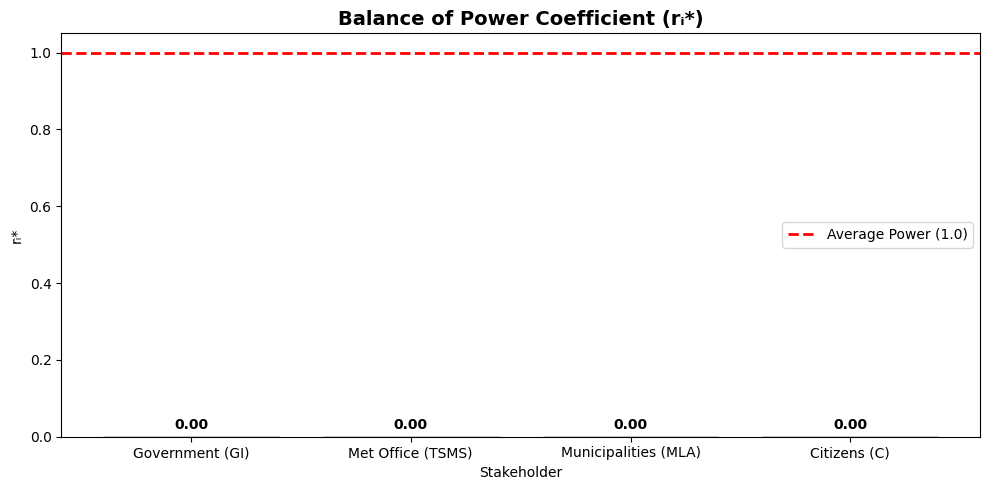

  ✅ Saved 01_power_histogram.png


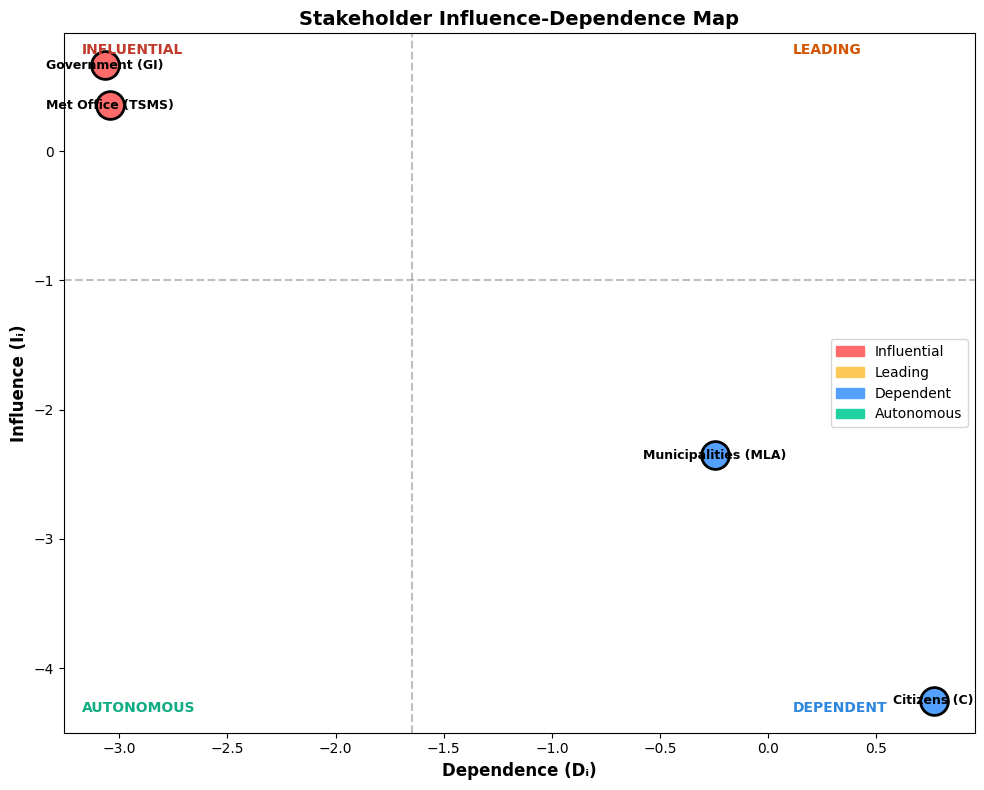

  ✅ Saved 02_stakeholder_map.png


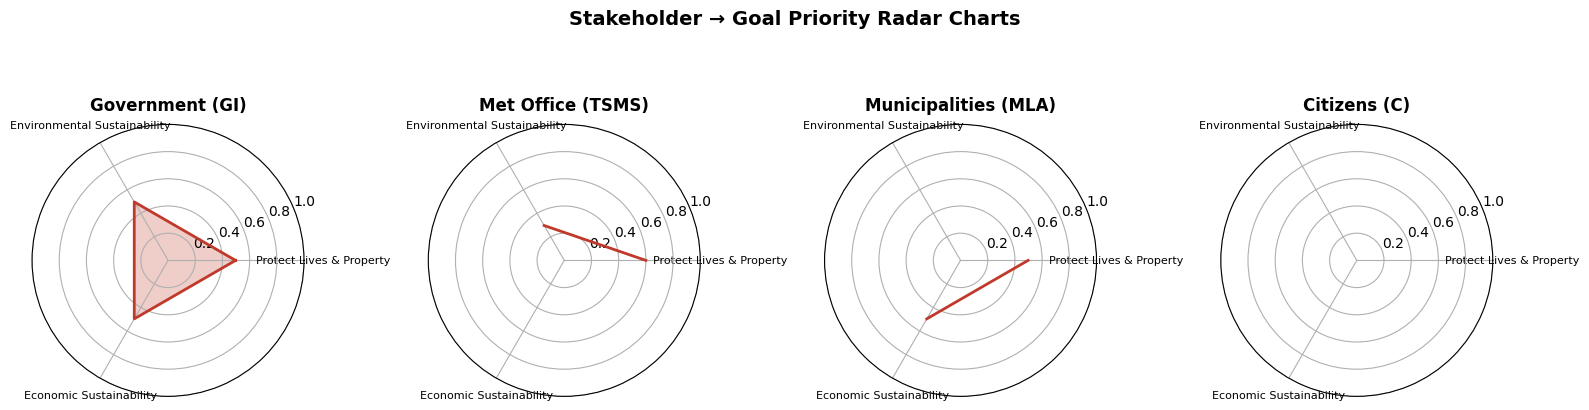

  ✅ Saved 03_radar_charts.png


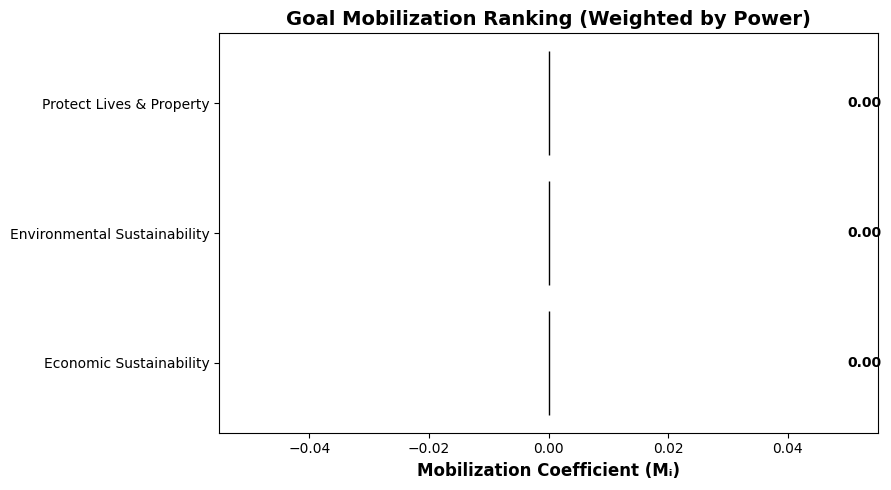

  ✅ Saved 04_mobilization_bars.png


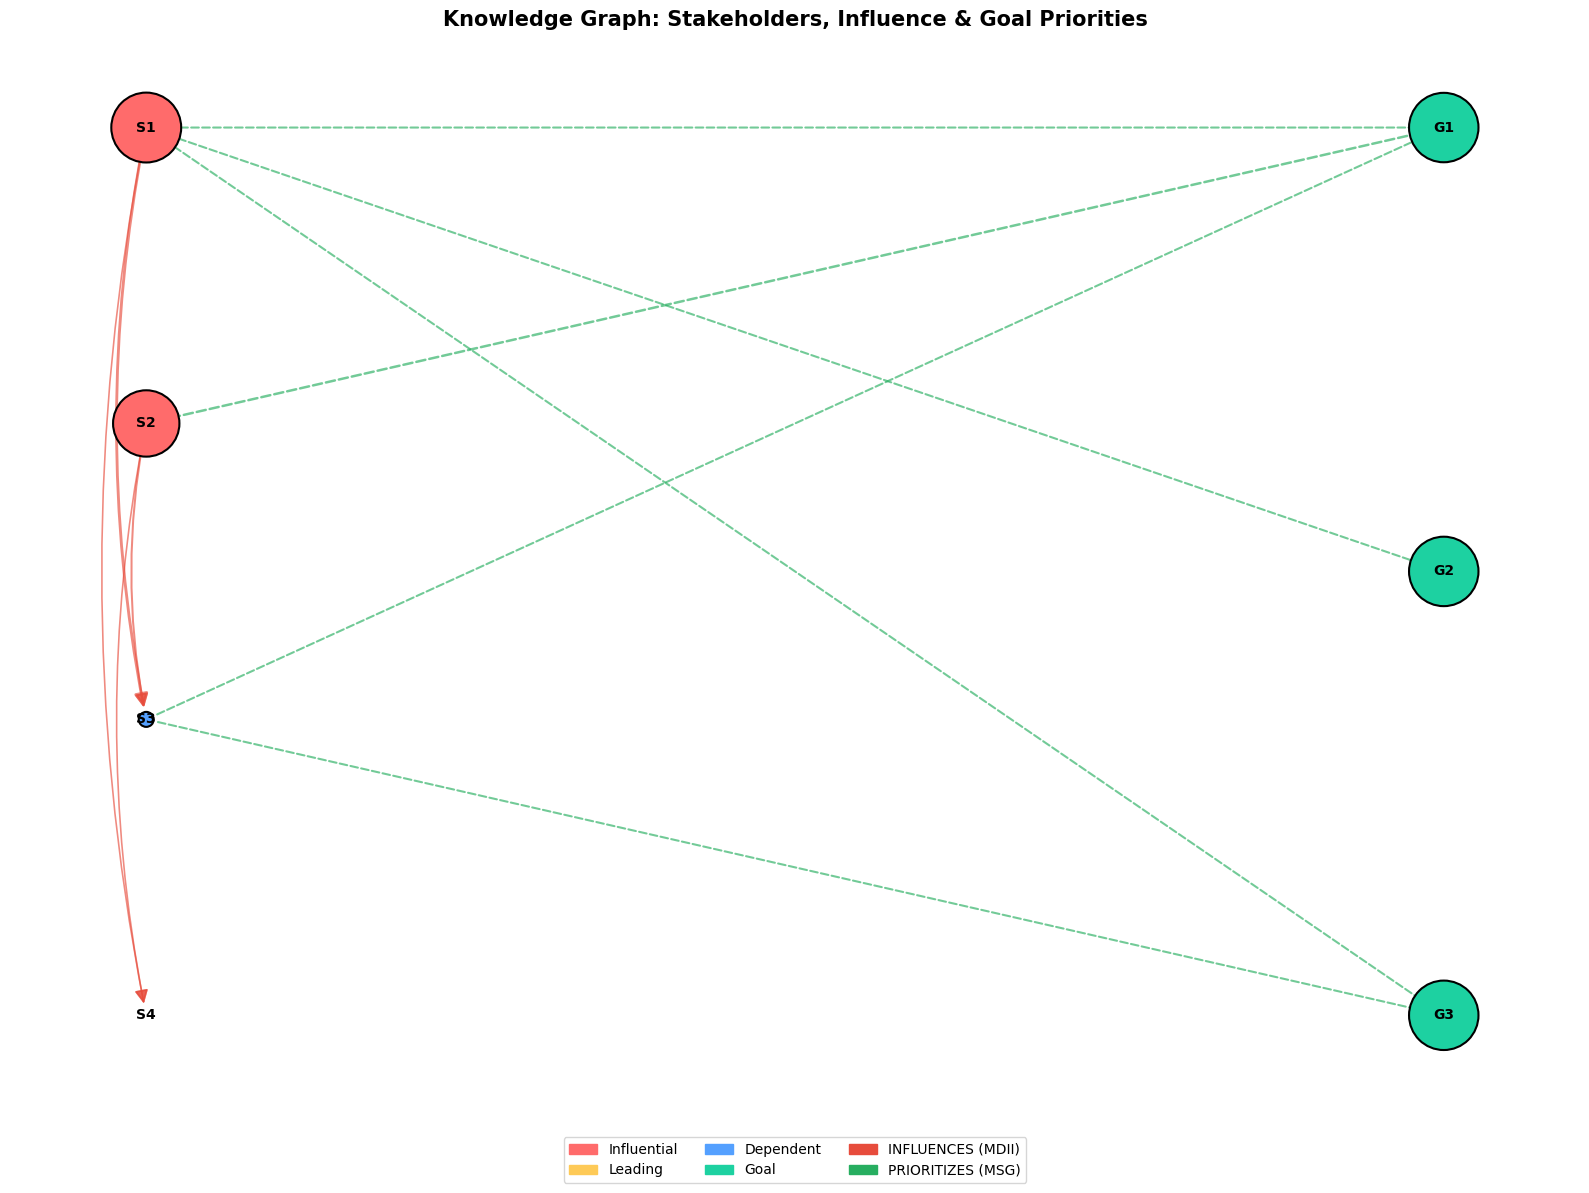

  ✅ Saved 05_knowledge_graph.png

📊 FINAL RESULTS SUMMARY

🏆 POWER RANKING (rᵢ* Coefficient):
  Rank 1: Government (GI)                rᵢ* = 0.0000 [Influential]
  Rank 1: Met Office (TSMS)              rᵢ* = 0.0000 [Influential]
  Rank 1: Municipalities (MLA)           rᵢ* = 0.0000 [Dependent]
  Rank 1: Citizens (C)                   rᵢ* = 0.0000 [Dependent]

🎯 GOAL MOBILIZATION RANKING:
  Rank 1: Protect Lives & Property                 Mᵢ = 0.0000
  Rank 1: Environmental Sustainability             Mᵢ = 0.0000
  Rank 1: Economic Sustainability                  Mᵢ = 0.0000

💡 KEY INSIGHT: 'Protect Lives & Property' is the highest-mobilization goal.
   'Government (GI)' is the most powerful stakeholder (rᵢ* = 0.00).

📁 All PNG outputs saved to: /content/if_mactor_outputs



In [15]:
# ═══════════════════════════════════════════════════════════════════
# DUMMY DATA — 4 Stakeholders, 3 Goals, 2 Experts
# ═══════════════════════════════════════════════════════════════════

stakeholders = ['S1', 'S2', 'S3', 'S4']
goals = ['G1', 'G2', 'G3']

stakeholder_labels = {
    'S1': 'Government (GI)',
    'S2': 'Met Office (TSMS)',
    'S3': 'Municipalities (MLA)',
    'S4': 'Citizens (C)',
}
goal_labels = {
    'G1': 'Protect Lives & Property',
    'G2': 'Environmental Sustainability',
    'G3': 'Economic Sustainability',
}

# ------- Expert surveys: Stakeholder → Stakeholder influence -------
influence_surveys = {
    'E1': {
        'S1': {'S1': '-',  'S2': 'VH', 'S3': 'H',  'S4': 'MH'},
        'S2': {'S1': 'MH', 'S2': '-',  'S3': 'VH', 'S4': 'L'},
        'S3': {'S1': 'L',  'S2': 'ML', 'S3': '-',  'S4': 'VH'},
        'S4': {'S1': 'VL', 'S2': 'VL', 'S3': 'ML', 'S4': '-'},
    },
    'E2': {
        'S1': {'S1': '-',  'S2': 'H',  'S3': 'VH', 'S4': 'MH'},
        'S2': {'S1': 'H',  'S2': '-',  'S3': 'H',  'S4': 'ML'},
        'S3': {'S1': 'ML', 'S2': 'L',  'S3': '-',  'S4': 'VH'},
        'S4': {'S1': 'L',  'S2': 'VL', 'S3': 'L',  'S4': '-'},
    },
}

# ------- Expert surveys: Stakeholder → Goal priority -------
goal_surveys = {
    'E1': {
        'S1': {'G1': 'VH', 'G2': 'H',  'G3': 'VH'},
        'S2': {'G1': 'VH', 'G2': 'MH', 'G3': 'L'},
        'S3': {'G1': 'H',  'G2': 'L',  'G3': 'H'},
        'S4': {'G1': 'H',  'G2': 'VL', 'G3': 'VL'},
    },
    'E2': {
        'S1': {'G1': 'H',  'G2': 'VH', 'G3': 'H'},
        'S2': {'G1': 'VH', 'G2': 'H',  'G3': 'VL'},
        'S3': {'G1': 'VH', 'G2': 'ML', 'G3': 'VH'},
        'S4': {'G1': 'MH', 'G2': 'L',  'G3': 'L'},
    },
}

expert_weights = {'E1': 0.5, 'E2': 0.5}

# ------- Run the full workflow -------
results = run_workflow(
    influence_surveys=influence_surveys,
    goal_surveys=goal_surveys,
    stakeholders=stakeholders,
    goals=goals,
    expert_weights=expert_weights,
    stakeholder_labels=stakeholder_labels,
    goal_labels=goal_labels,
)

In [16]:
# Display every results table
for name, df in results.items():
    print("\n" + "─"*70)
    print(f"📋 {name}")
    print("─"*70)
    display(df)

# Verify PNGs on disk
import os
print("\n" + "="*70)
print("📁 Generated PNG files:")
for f in sorted(os.listdir(OUTPUT_DIR)):
    size_kb = os.path.getsize(os.path.join(OUTPUT_DIR, f)) / 1024
    print(f"  • {f}  ({size_kb:.1f} KB)")
print("="*70)


──────────────────────────────────────────────────────────────────────
📋 MDI (Direct Influence)
──────────────────────────────────────────────────────────────────────


,S1,S2,S3,S4
S1,0.0000,0.4966,0.4966,0.2000
S2,0.2961,0.0000,0.4966,-0.3073
S3,-0.3073,-0.3073,0.0000,0.6000
S4,-0.5106,-0.6000,-0.3073,0.0000



──────────────────────────────────────────────────────────────────────
📋 MDII (Direct + Indirect)
──────────────────────────────────────────────────────────────────────


,S1,S2,S3,S4
S1,0.0000,-0.4107,0.6859,0.3893
S2,-0.5218,0.0000,0.4854,0.3893
S3,-1.1252,-1.2146,0.0000,-0.0146
S4,-1.4179,-1.4179,-1.4179,0.0000



──────────────────────────────────────────────────────────────────────
📋 Power & Dependence
──────────────────────────────────────────────────────────────────────


,Iᵢ (Influence),Dᵢ (Dependence),rᵢ (Raw Power),rᵢ* (Coefficient),Rank
S1,0.6645,-3.0649,0.0,0.0,1
S2,0.3529,-3.0432,0.0,0.0,1
S3,-2.3544,-0.2466,0.0,0.0,1
S4,-4.2537,0.7640,0.0,0.0,1


... (5 outputs left out)

,G1,G2,G3
S1,0.0,0.0,0.0
S2,0.0,0.0,-0.0
S3,0.0,-0.0,0.0
S4,0.0,-0.0,-0.0



──────────────────────────────────────────────────────────────────────
📋 Goal Mobilization
──────────────────────────────────────────────────────────────────────


,Mᵢ (Mobilization),Rank
G1,0.0,1
G2,0.0,1
G3,0.0,1



📁 Generated PNG files:
  • 01_power_histogram.png  (43.0 KB)
  • 02_stakeholder_map.png  (75.7 KB)
  • 03_radar_charts.png  (229.9 KB)
  • 04_mobilization_bars.png  (45.7 KB)
  • 05_knowledge_graph.png  (257.4 KB)


In [17]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx

def plot_flowchart_diagram(mdii_df, msg_df, power_df, categories,
                           stakeholder_labels=None, goal_labels=None,
                           save_path=None):
    """
    Generates a structured hierarchical flowchart diagram (like the user's image)
    showing Stakeholders in the middle and Goals at the bottom.
    """
    stakeholders = list(mdii_df.index)
    goals = list(msg_df.columns)

    # Use labels if provided, otherwise use IDs
    s_labels = stakeholder_labels or {s: s for s in stakeholders}
    g_labels = goal_labels or {g: g for g in goals}

    fig, ax = plt.subplots(figsize=(14, 10))
    G = nx.DiGraph()

    # ─── 1. Calculate Node Positions ──────────────────────────────────
    pos = {}

    # Stakeholders: Vertically stacked in the middle, slightly zigzagged
    n_s = len(stakeholders)
    for i, s in enumerate(stakeholders):
        y = 0.8 - (i * (0.5 / max(1, n_s - 1)))  # Spread from y=0.8 down to y=0.3
        x = 0.5 + (0.05 if i % 2 == 0 else -0.05) # Slight zigzag
        pos[s] = (x, y)

    # Goals: Horizontally aligned at the bottom
    n_g = len(goals)
    if n_g > 1:
        x_goals = [0.15 + (i * (0.7 / (n_g - 1))) for i in range(n_g)]
    else:
        x_goals = [0.5]

    for i, g in enumerate(goals):
        pos[g] = (x_goals[i], 0.05)

    # ─── 2. Draw Nodes ───────────────────────────────────────────────
    color_map = {'Influential': '#ff85e1', 'Leading': '#fceb7c',
                 'Dependent': '#85f2f2', 'Autonomous': '#a3f78a'}

    # Draw Stakeholders
    for s in stakeholders:
        cat = categories[s]
        inf = power_df.loc[s, 'Iᵢ (Influence)']
        node_text = f"{s_labels[s]}\nInfluence: {inf:.2f}\nCategory: {cat}"

        ax.scatter(pos[s][0], pos[s][1], s=3500, color=color_map[cat],
                   edgecolor='black', linewidth=1.5, zorder=3)
        ax.text(pos[s][0], pos[s][1], node_text, ha='center', va='center',
                fontsize=8, fontweight='bold', zorder=4)

    # Draw Goals
    for g in goals:
        mob = power_df  # placeholder
        node_text = g_labels[g]

        ax.scatter(pos[g][0], pos[g][1], s=3000, color='#bdfcb5',
                   edgecolor='black', linewidth=1.5, zorder=3)
        ax.text(pos[g][0], pos[g][1], node_text, ha='center', va='center',
                fontsize=9, fontweight='bold', zorder=4)

    # ─── 3. Draw Edges (Curved Arrows) ───────────────────────────────

    # A. Stakeholder → Stakeholder (Influences)
    for i, si in enumerate(stakeholders):
        for j, sj in enumerate(stakeholders):
            if i == j: continue
            weight = mdii_df.loc[si, sj]
            if weight > 0.05:
                # Draw curved arrow
                arrow = mpatches.FancyArrowPatch(
                    pos[si], pos[sj],
                    connectionstyle=f"arc3,rad={0.2 if j > i else -0.2}",
                    arrowstyle='->', mutation_scale=15,
                    color='gray', lw=1.5, alpha=0.6, zorder=2
                )
                ax.add_patch(arrow)
                # Add weight label near the midpoint
                mid_x = (pos[si][0] + pos[sj][0]) / 2
                mid_y = (pos[si][1] + pos[sj][1]) / 2
                ax.text(mid_x, mid_y, f"{weight:.2f}", fontsize=7,
                        color='black', ha='center', va='center', zorder=5,
                        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1))

    # B. Stakeholder → Goal (Priorities)
    for s in stakeholders:
        for g in goals:
            weight = msg_df.loc[s, g]
            if weight > 0.05:
                arrow = mpatches.FancyArrowPatch(
                    pos[s], pos[g],
                    connectionstyle="arc3,rad=0.1",
                    arrowstyle='->', mutation_scale=15,
                    color='green', lw=1.5, alpha=0.5, zorder=2
                )
                ax.add_patch(arrow)
                # Add weight label
                mid_x = (pos[s][0] + pos[g][0]) / 2
                mid_y = (pos[s][1] + pos[g][1]) / 2
                ax.text(mid_x, mid_y, f"{weight:.2f}", fontsize=7,
                        color='darkgreen', ha='center', va='center', zorder=5,
                        bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1))

    # ─── 4. Final Layout Touches ─────────────────────────────────────
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 0.9)
    ax.axis('off')
    ax.set_title("IF-MACTOR Relational Diagram", fontsize=16, fontweight='bold', pad=20)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"  ✅ Saved {save_path}")

    plt.show()
    plt.close()

In [20]:
import pandas as pd

def generate_policy_insights(power_df, msg_df, mobil_df, categories,
                             stakeholder_labels, goal_labels):
    """
    Generates a highly formatted, text-based executive summary for policymakers.
    """
    print("\n" + "█"*75)
    print("📋 POLICY MAKER EXECUTIVE SUMMARY: STAKEHOLDER & GOAL INSIGHTS")
    print("█"*75)

    # ─── 1. THE POWERHOUSES (Influential) ────────────────────────────
    print("\n👑 1. THE POWERHOUSES (Influential Stakeholders)")
    print("   These actors hold the most power and influence others. They must lead.")
    print("   " + "-"*71)

    influential = [s for s, cat in categories.items() if cat == 'Influential']
    if not influential:
        print("   ⚠️ No single dominant powerhouse found. Power is distributed.")
    else:
        for s in influential:
            r_star = power_df.loc[s, 'rᵢ* (Coefficient)']
            # Find what they care about most
            top_goal_id = msg_df.loc[s].idxmax()
            top_goal_name = goal_labels.get(top_goal_id, top_goal_id)
            top_goal_score = msg_df.loc[s, top_goal_id]

            print(f"   • {stakeholder_labels.get(s, s)} (Power Score: {r_star:.2f})")
            print(f"     └─ Main Focus: **{top_goal_name}** (Priority: {top_goal_score:.2f})")
            print(f"     └─ Role: Driver of policy and resource allocation.\n")

    # ─── 2. THE MANAGERS (Leading) ───────────────────────────────────
    print("⚙️ 2. THE MANAGERS (Leading Stakeholders)")
    print("   These actors are heavily involved. They influence others, but are also")
    print("   influenced. They are the 'bridge' between policy and execution.")
    print("   " + "-"*71)

    leading = [s for s, cat in categories.items() if cat == 'Leading']
    if not leading:
        print("   No 'Leading' (actively engaged) stakeholders found.\n")
    else:
        for s in leading:
            r_star = power_df.loc[s, 'rᵢ* (Coefficient)']
            top_goal_id = msg_df.loc[s].idxmax()
            top_goal_name = goal_labels.get(top_goal_id, top_goal_id)

            print(f"   • {stakeholder_labels.get(s, s)} (Power Score: {r_star:.2f})")
            print(f"     └─ Main Focus: **{top_goal_name}**")
            print(f"     └─ Role: Coordinator and implementer.\n")

    # ─── 3. THE VULNERABLE / IMPLEMENTERS (Dependent) ────────────────
    print("🛡️ 3. THE VULNERABLE & IMPLEMENTERS (Dependent Stakeholders)")
    print("   These actors have little power to change the system, but they are")
    print("   heavily impacted by it. They need protection and resources.")
    print("   " + "-"*71)

    dependent = [s for s, cat in categories.items() if cat == 'Dependent']
    if not dependent:
        print("   No 'Dependent' stakeholders found.\n")
    else:
        for s in dependent:
            r_star = power_df.loc[s, 'rᵢ* (Coefficient)']
            top_goal_id = msg_df.loc[s].idxmax()
            top_goal_name = goal_labels.get(top_goal_id, top_goal_id)

            print(f"   • {stakeholder_labels.get(s, s)} (Power Score: {r_star:.2f})")
            print(f"     └─ Main Priority: **{top_goal_name}**")
            print(f"     └─ Role: Receiver of policies; must be consulted to avoid backlash.\n")

    # ─── 4. AUTONOMOUS (Isolated) ────────────────────────────────────
    autonomous = [s for s, cat in categories.items() if cat == 'Autonomous']
    if autonomous:
        print("🐺 4. AUTONOMOUS STAKEHOLDERS")
        print("   These actors operate in silos. They have low influence and low dependence.")
        print("   " + "-"*71)
        for s in autonomous:
            print(f"   • {stakeholder_labels.get(s, s)}: Operating independently. Needs integration.\n")

    # ─── 5. GOAL ALIGNMENT & CONFLICTS ───────────────────────────────
    print("🎯 5. GOAL MOBILIZATION & STRATEGIC CONFLICTS")
    print("   Which goals have the most momentum, and where will the battles be?")
    print("   " + "-"*71)

    top_goal = mobil_df.index[0]
    second_goal = mobil_df.index[1] if len(mobil_df) > 1 else None
    lowest_goal = mobil_df.index[-1]

    print(f"   🥇 **WINNER GOAL**: '{goal_labels.get(top_goal, top_goal)}' (Score: {mobil_df.loc[top_goal, 'Mᵢ (Mobilization)']:.2f})")
    print(f"      └─ Insight: This goal is backed by powerful stakeholders. It is politically 'safe' to fund.")

    if second_goal:
        print(f"   🥈 **RUNNER-UP**: '{goal_labels.get(second_goal, second_goal)}' (Score: {mobil_df.loc[second_goal, 'Mᵢ (Mobilization)']:.2f})")

    print(f"   🚨 **NEGLECTED GOAL**: '{goal_labels.get(lowest_goal, lowest_goal)}' (Score: {mobil_df.loc[lowest_goal, 'Mᵢ (Mobilization)']:.2f})")
    print(f"      └─ Insight: This goal has the least backing from powerful actors. If you fund this, expect resistance or lack of implementation power.\n")

    # ─── 6. DYNAMIC POLICY RECOMMENDATIONS ───────────────────────────
    print("💡 6. STRATEGIC RECOMMENDATIONS FOR POLICY MAKERS")
    print("   " + "-"*71)

    top_power_id = power_df.index[0]
    print(f"   Action 1: Secure the buy-in of {stakeholder_labels.get(top_power_id, top_power_id)}.")
    print(f"             They are the most powerful actor. Without them, no policy will pass.")

    if dependent:
        dep_id = dependent[0]
        print(f"   Action 2: Fund awareness or protection programs for {stakeholder_labels.get(dep_id, dep_id)}.")
        print(f"             They are highly dependent and vulnerable. Neglecting them poses a social risk.")

    # Check if top power and top goal are misaligned
    top_power_focus = msg_df.loc[top_power_id].idxmax()
    if top_power_focus != top_goal:
        print(f"   ⚠️ CONFLICT ALERT: The most powerful actor cares most about '{goal_labels.get(top_power_focus, top_power_focus)}',")
        print(f"      but the network's consensus is '{goal_labels.get(top_goal, top_goal)}'. You must broker a compromise here.")
    else:
        print(f"   ✅ ALIGNMENT STRENGTH: The most powerful actor's priority aligns with the network's top goal.")

    print("\n" + "█"*75 + "\n")

  ✅ Saved /content/if_mactor_outputs/06_relational_diagram.png


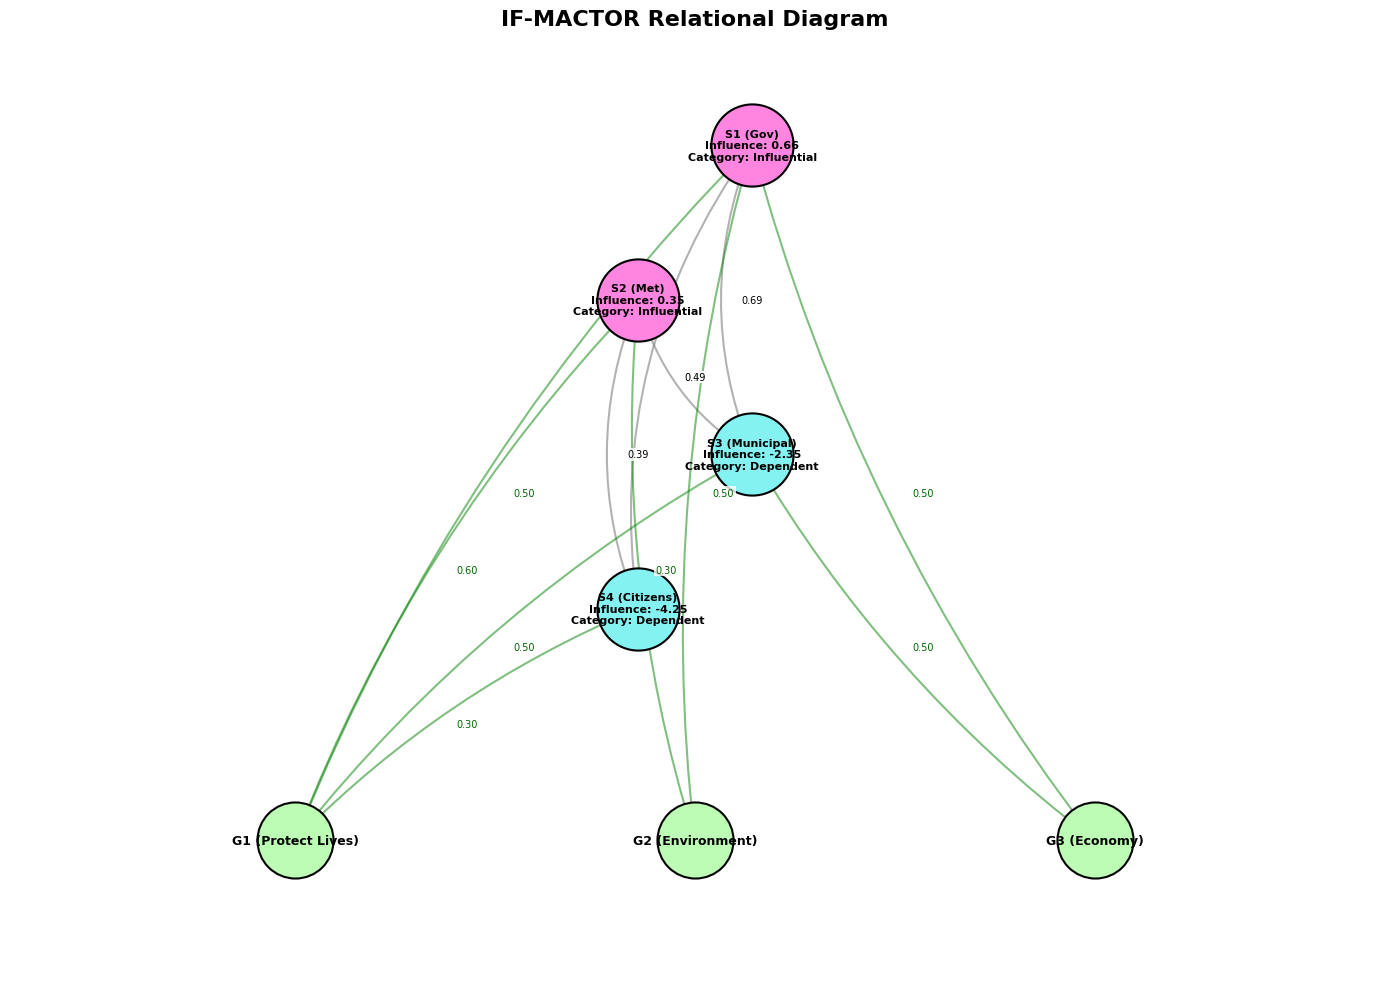

In [18]:
# Reconstruct the intermediate data from the run_workflow test
mdi_df_test = build_mdi_matrix(influence_surveys, stakeholders, expert_weights)
mdii_df_test = compute_mdii(mdi_df_test)
I, D = compute_influence_dependence(mdii_df_test)
power_df_test, r_dict = compute_balance_of_power(I, D, mdii_df_test)
categories_test, _, _ = categorize_stakeholders(power_df_test)
msg_df_test = build_stakeholder_goal_matrix(goal_surveys, stakeholders, goals, expert_weights)

# Generate the diagram
plot_flowchart_diagram(
    mdii_df=mdii_df_test,
    msg_df=msg_df_test,
    power_df=power_df_test,
    categories=categories_test,
    stakeholder_labels={
        'S1': 'S1 (Gov)',
        'S2': 'S2 (Met)',
        'S3': 'S3 (Municipal)',
        'S4': 'S4 (Citizens)'
    },
    goal_labels={
        'G1': 'G1 (Protect Lives)',
        'G2': 'G2 (Environment)',
        'G3': 'G3 (Economy)'
    },
    save_path="/content/if_mactor_outputs/06_relational_diagram.png"
)

In [21]:
print("GENERATING INSIGHTS FOR USE CASE 1 (TURKEY)...")
generate_policy_insights(
    power_df=results['Power & Dependence'],
    msg_df=results['MSG (Stakeholder-Goal)'],
    mobil_df=results['Goal Mobilization'],
    categories={s: cat for s, cat in results['Stakeholder Categories']['Category'].items()},
    stakeholder_labels=stakeholder_labels,
    goal_labels=goal_labels
)

GENERATING INSIGHTS FOR USE CASE 1 (TURKEY)...

███████████████████████████████████████████████████████████████████████████
📋 POLICY MAKER EXECUTIVE SUMMARY: STAKEHOLDER & GOAL INSIGHTS
███████████████████████████████████████████████████████████████████████████

👑 1. THE POWERHOUSES (Influential Stakeholders)
   These actors hold the most power and influence others. They must lead.
   -----------------------------------------------------------------------
   • Government (GI) (Power Score: 0.00)
     └─ Main Focus: **Protect Lives & Property** (Priority: 0.50)
     └─ Role: Driver of policy and resource allocation.

   • Met Office (TSMS) (Power Score: 0.00)
     └─ Main Focus: **Protect Lives & Property** (Priority: 0.60)
     └─ Role: Driver of policy and resource allocation.

⚙️ 2. THE MANAGERS (Leading Stakeholders)
   These actors are heavily involved. They influence others, but are also
   influenced. They are the 'bridge' between policy and execution.
   ------------------------

**use case two **

🌊 STARTING USE CASE 2: COASTAL CITY FLOOD RESILIENCE


🚀 RUNNING IF-MACTOR FLOOD RISK MANAGEMENT WORKFLOW

[STAGE 2] Analyzing stakeholder-to-stakeholder influence...
  ✅ MDI matrix built ((6, 6))
  ✅ MDII matrix built (indirect influence incorporated)
  ✅ Influence & Dependence computed
  ✅ Balance of Power (rᵢ*) computed

    Iᵢ (Influence)  Dᵢ (Dependence)  rᵢ (Raw Power)  rᵢ* (Coefficient)  Rank
S6          4.5839           0.6666        0.542142             2.8455     1
S2          2.7295           0.3109        0.331955             1.7423     2
S1          2.8443           3.7163        0.167052             0.8768     3
S4          1.3208           1.3873        0.087268             0.4580     4
S5         -0.3402           1.4042        0.014736             0.0773     5
S3         -3.7566          -0.1036       -0.000000            -0.0000     6

  Stakeholder Categories: {'S6': 'Influential', 'S2': 'Influential', 'S1': 'Leading', 'S4': 'Dependent', 'S5': 'Dependent', 'S3': 'Aut

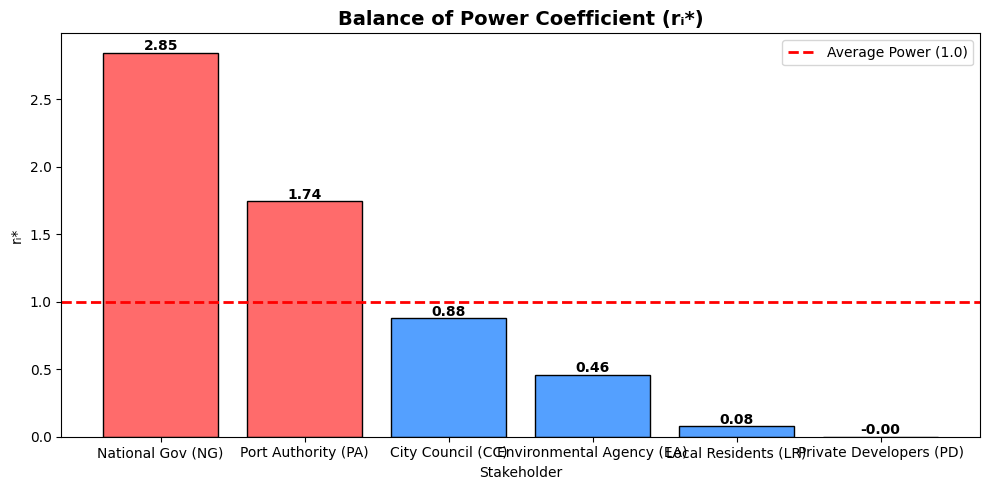

  ✅ Saved 01_power_histogram.png


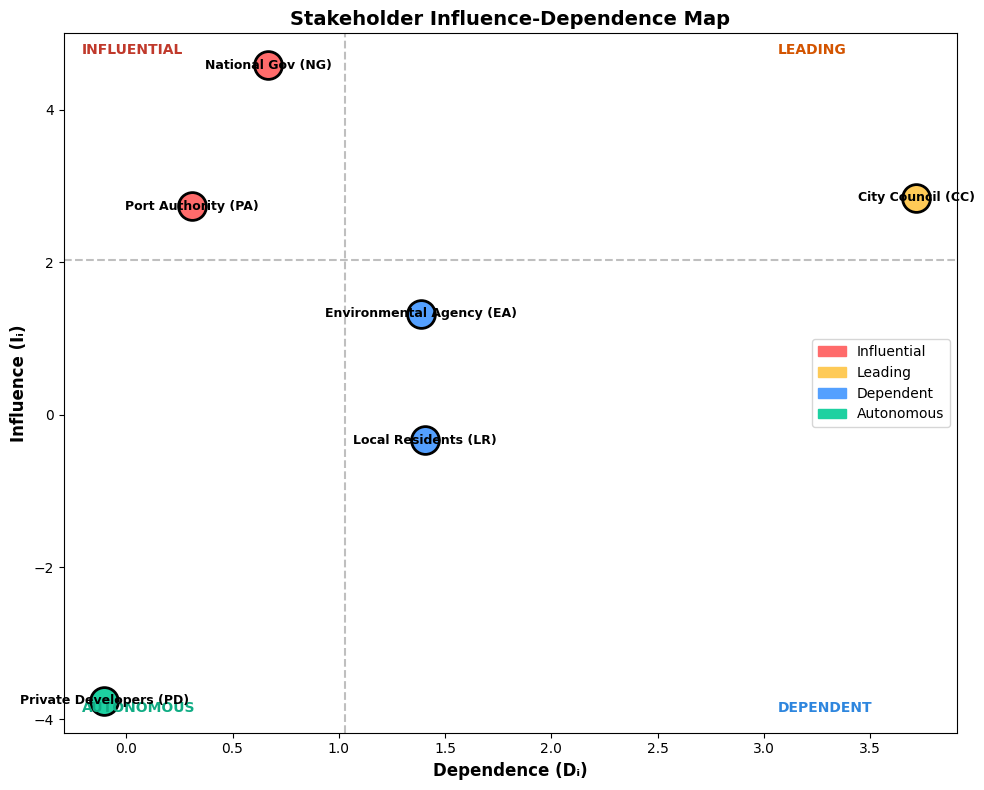

  ✅ Saved 02_stakeholder_map.png


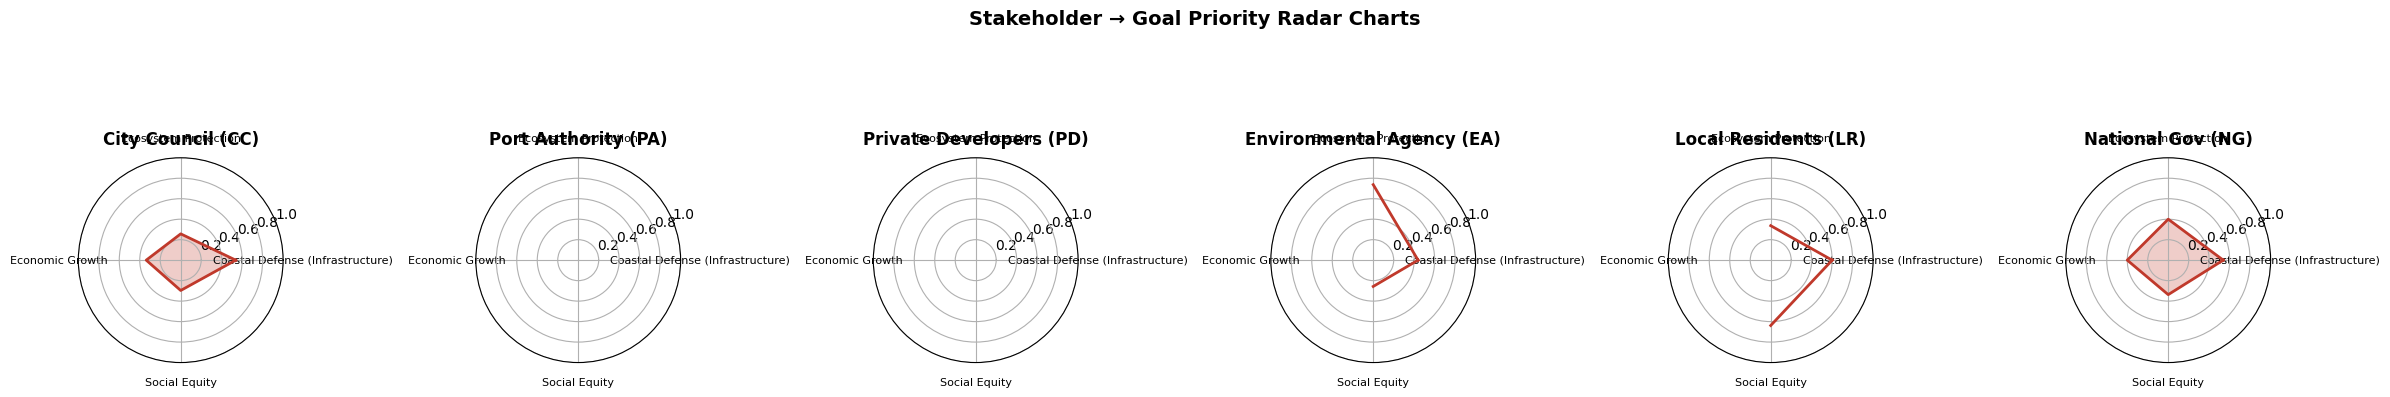

  ✅ Saved 03_radar_charts.png


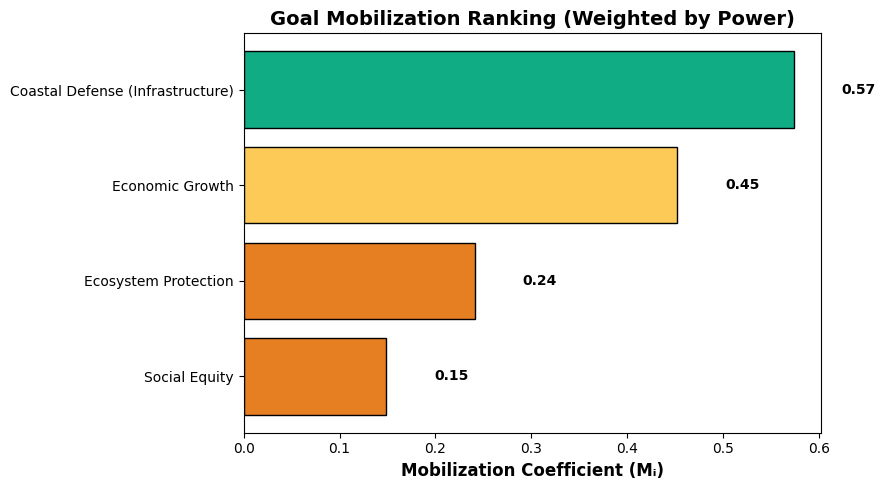

  ✅ Saved 04_mobilization_bars.png


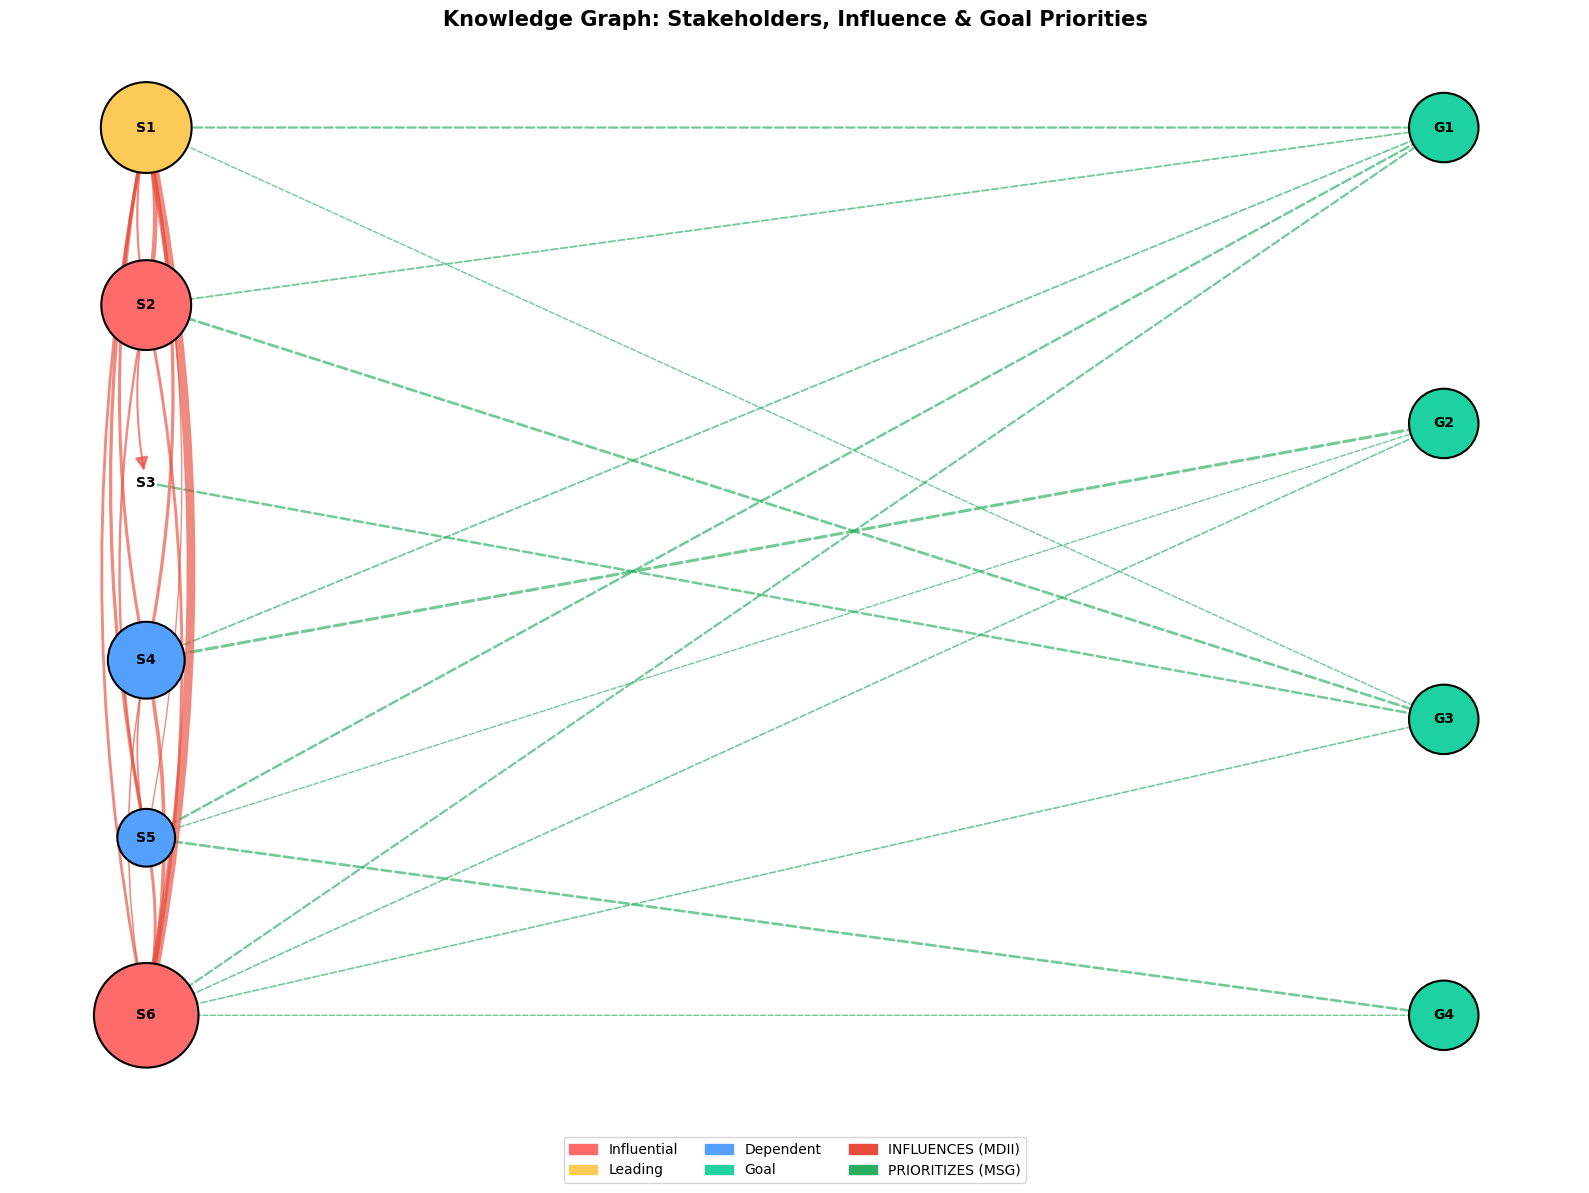

  ✅ Saved 05_knowledge_graph.png

📊 FINAL RESULTS SUMMARY

🏆 POWER RANKING (rᵢ* Coefficient):
  Rank 1: National Gov (NG)              rᵢ* = 2.8455 [Influential]
  Rank 2: Port Authority (PA)            rᵢ* = 1.7423 [Influential]
  Rank 3: City Council (CC)              rᵢ* = 0.8768 [Leading]
  Rank 4: Environmental Agency (EA)      rᵢ* = 0.4580 [Dependent]
  Rank 5: Local Residents (LR)           rᵢ* = 0.0773 [Dependent]
  Rank 6: Private Developers (PD)        rᵢ* = -0.0000 [Autonomous]

🎯 GOAL MOBILIZATION RANKING:
  Rank 1: Coastal Defense (Infrastructure)         Mᵢ = 0.5733
  Rank 2: Economic Growth                          Mᵢ = 0.4520
  Rank 3: Ecosystem Protection                     Mᵢ = 0.2408
  Rank 4: Social Equity                            Mᵢ = 0.1489

💡 KEY INSIGHT: 'Coastal Defense (Infrastructure)' is the highest-mobilization goal.
   'National Gov (NG)' is the most powerful stakeholder (rᵢ* = 2.85).

📁 All PNG outputs saved to: /content/if_mactor_use_case_2

  ✅ Saved

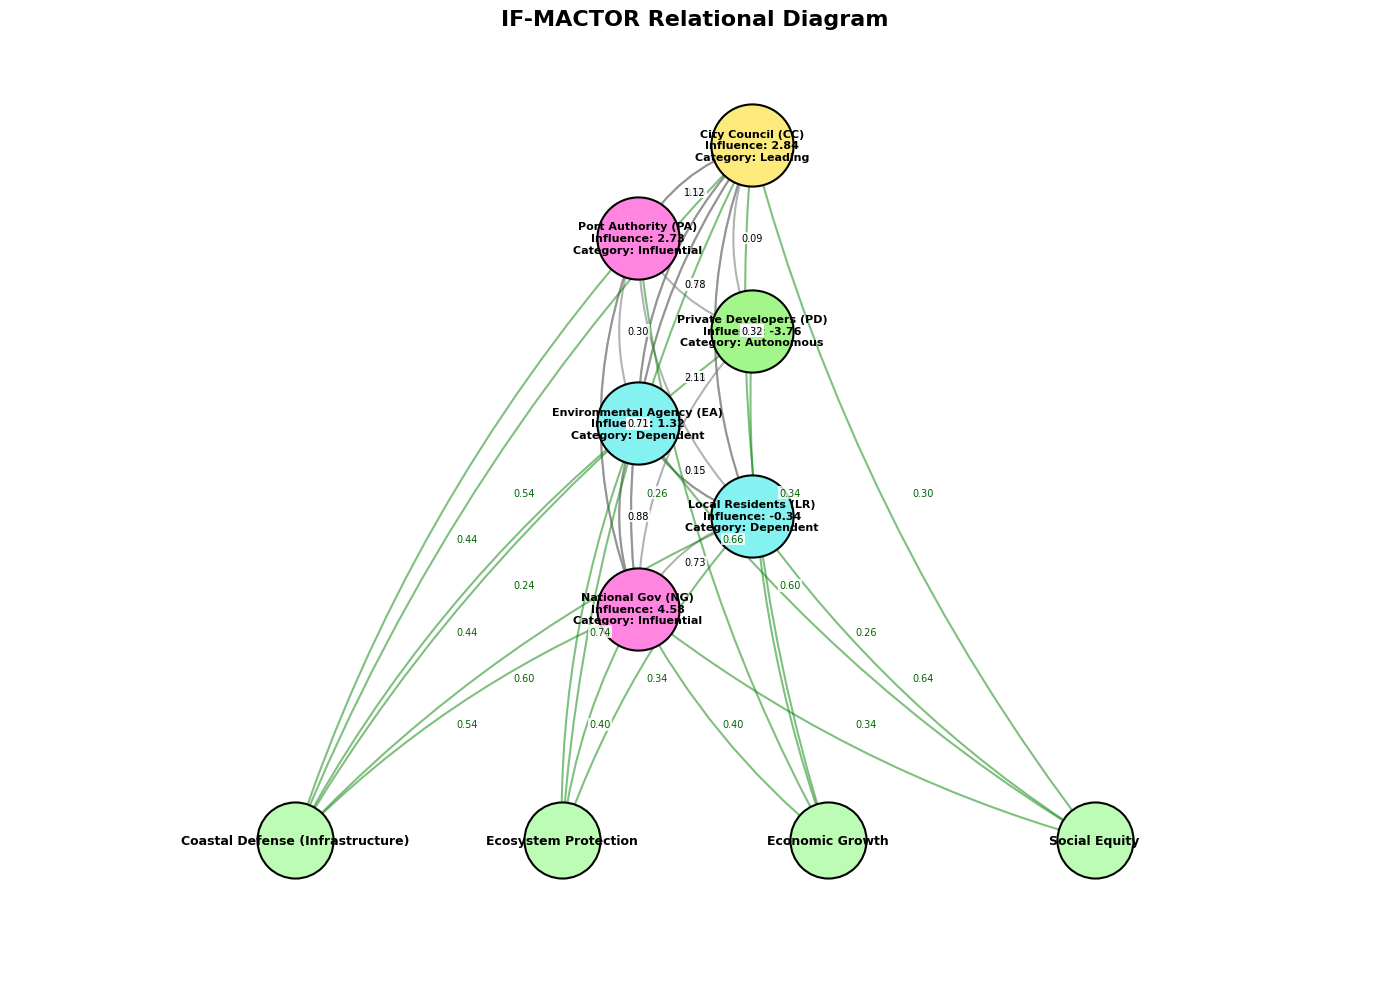

In [19]:
# ═══════════════════════════════════════════════════════════════════
# NEW USE CASE: Coastal City Flood Resilience Project
# ═══════════════════════════════════════════════════════════════════

# 1. Define Stakeholders and Goals
stakeholders_2 = ['S1', 'S2', 'S3', 'S4', 'S5', 'S6']
goals_2 = ['G1', 'G2', 'G3', 'G4']

stakeholder_labels_2 = {
    'S1': 'City Council (CC)',
    'S2': 'Port Authority (PA)',
    'S3': 'Private Developers (PD)',
    'S4': 'Environmental Agency (EA)',
    'S5': 'Local Residents (LR)',
    'S6': 'National Gov (NG)'
}

goal_labels_2 = {
    'G1': 'Coastal Defense (Infrastructure)',
    'G2': 'Ecosystem Protection',
    'G3': 'Economic Growth',
    'G4': 'Social Equity'
}

# 2. Define Expert Weights (Unequal Weights)
# Expert 1 (Chief Engineer) is the most senior, Expert 3 (Junior Planner) is least.
expert_weights_2 = {'E1': 0.50, 'E2': 0.30, 'E3': 0.20}

# 3. Dummy Survey Data: Stakeholder-to-Stakeholder Influence
influence_surveys_2 = {
    'E1': {
        'S1': {'S1': '-', 'S2': 'H',  'S3': 'MH', 'S4': 'VH', 'S5': 'VH', 'S6': 'MH'},
        'S2': {'S1': 'VH','S2': '-',  'S3': 'AH', 'S4': 'MH', 'S5': 'ML', 'S6': 'H'},
        'S3': {'S1': 'MH','S2': 'MH', 'S3': '-',  'S4': 'VL', 'S5': 'ML', 'S6': 'L'},
        'S4': {'S1': 'H', 'S2': 'MH', 'S3': 'L',  'S4': '-',  'S5': 'H',  'S6': 'MH'},
        'S5': {'S1': 'VH','S2': 'L',  'S3': 'L',  'S4': 'MH', 'S5': '-',  'S6': 'MH'},
        'S6': {'S1': 'AH','S2': 'H',  'S3': 'MH', 'S4': 'H',  'S5': 'MH', 'S6': '-'}
    },
    'E2': {
        'S1': {'S1': '-', 'S2': 'MH', 'S3': 'MH', 'S4': 'H',  'S5': 'H',  'S6': 'H'},
        'S2': {'S1': 'H', 'S2': '-',  'S3': 'AH', 'S4': 'H',  'S5': 'L',  'S6': 'MH'},
        'S3': {'S1': 'H', 'S2': 'H',  'S3': '-',  'S4': 'VL', 'S5': 'ML', 'S6': 'L'},
        'S4': {'S1': 'H', 'S2': 'ML', 'S3': 'L',  'S4': '-',  'S5': 'VH', 'S6': 'H'},
        'S5': {'S1': 'VH','S2': 'ML', 'S3': 'ML', 'S4': 'H',  'S5': '-',  'S6': 'MH'},
        'S6': {'S1': 'AH','S2': 'H',  'S3': 'H',  'S4': 'H',  'S5': 'H',  'S6': '-'}
    },
    'E3': {
        'S1': {'S1': '-', 'S2': 'H',  'S3': 'H',  'S4': 'VH', 'S5': 'VH', 'S6': 'MH'},
        'S2': {'S1': 'VH','S2': '-',  'S3': 'VH', 'S4': 'MH', 'S5': 'ML', 'S6': 'H'},
        'S3': {'S1': 'MH','S2': 'MH', 'S3': '-',  'S4': 'L',  'S5': 'ML', 'S6': 'ML'},
        'S4': {'S1': 'H', 'S2': 'MH', 'S3': 'L',  'S4': '-',  'S5': 'H',  'S6': 'MH'},
        'S5': {'S1': 'H', 'S2': 'L',  'S3': 'L',  'S4': 'MH', 'S5': '-',  'S6': 'MH'},
        'S6': {'S1': 'AH','S2': 'H',  'S3': 'MH', 'S4': 'H',  'S5': 'MH', 'S6': '-'}
    }
}

# 4. Dummy Survey Data: Stakeholder-to-Goal Priorities
goal_surveys_2 = {
    'E1': {
        'S1': {'G1': 'VH', 'G2': 'MH', 'G3': 'H',  'G4': 'MH'},
        'S2': {'G1': 'H',  'G2': 'ML', 'G3': 'VH', 'G4': 'L'},
        'S3': {'G1': 'MH', 'G2': 'L',  'G3': 'VH', 'G4': 'VL'},
        'S4': {'G1': 'H',  'G2': 'AH', 'G3': 'L',  'G4': 'MH'},
        'S5': {'G1': 'VH', 'G2': 'H',  'G3': 'L',  'G4': 'VH'},
        'S6': {'G1': 'VH', 'G2': 'H',  'G3': 'H',  'G4': 'H'}
    },
    'E2': {
        'S1': {'G1': 'H',  'G2': 'H',  'G3': 'MH', 'G4': 'H'},
        'S2': {'G1': 'H',  'G2': 'L',  'G3': 'AH', 'G4': 'ML'},
        'S3': {'G1': 'MH', 'G2': 'L',  'G3': 'VH', 'G4': 'VL'},
        'S4': {'G1': 'H',  'G2': 'VH', 'G3': 'L',  'G4': 'H'},
        'S5': {'G1': 'VH', 'G2': 'MH', 'G3': 'ML', 'G4': 'VH'},
        'S6': {'G1': 'H',  'G2': 'H',  'G3': 'H',  'G4': 'MH'}
    },
    'E3': {
        'S1': {'G1': 'VH', 'G2': 'MH', 'G3': 'H',  'G4': 'H'},
        'S2': {'G1': 'VH', 'G2': 'ML', 'G3': 'VH', 'G4': 'L'},
        'S3': {'G1': 'H',  'G2': 'L',  'G3': 'VH', 'G4': 'VL'},
        'S4': {'G1': 'VH', 'G2': 'AH', 'G3': 'L',  'G4': 'MH'},
        'S5': {'G1': 'VH', 'G2': 'H',  'G3': 'ML', 'G4': 'AH'},
        'S6': {'G1': 'VH', 'G2': 'H',  'G3': 'H',  'G4': 'H'}
    }
}

# ═══════════════════════════════════════════════════════════════════
# RUN THE WORKFLOW
# ═══════════════════════════════════════════════════════════════════
print("🌊 STARTING USE CASE 2: COASTAL CITY FLOOD RESILIENCE\n")

results_2 = run_workflow(
    influence_surveys=influence_surveys_2,
    goal_surveys=goal_surveys_2,
    stakeholders=stakeholders_2,
    goals=goals_2,
    expert_weights=expert_weights_2,
    stakeholder_labels=stakeholder_labels_2,
    goal_labels=goal_labels_2,
    output_dir='/content/if_mactor_use_case_2'
)

# ═══════════════════════════════════════════════════════════════════
# GENERATE THE FLOWCHART DIAGRAM
# ═══════════════════════════════════════════════════════════════════

# Reconstruct the intermediate data to pass to the diagram function
mdi_df_2 = build_mdi_matrix(influence_surveys_2, stakeholders_2, expert_weights_2)
mdii_df_2 = compute_mdii(mdi_df_2)
I_2, D_2 = compute_influence_dependence(mdii_df_2)
power_df_2, r_dict_2 = compute_balance_of_power(I_2, D_2, mdii_df_2)
categories_2, _, _ = categorize_stakeholders(power_df_2)
msg_df_2 = build_stakeholder_goal_matrix(goal_surveys_2, stakeholders_2, goals_2, expert_weights_2)

# Plot the flowchart (using the function we built previously)
plot_flowchart_diagram(
    mdii_df=mdii_df_2,
    msg_df=msg_df_2,
    power_df=power_df_2,
    categories=categories_2,
    stakeholder_labels=stakeholder_labels_2,
    goal_labels=goal_labels_2,
    save_path='/content/if_mactor_use_case_2/06_relational_diagram.png'
)

In [22]:
print("GENERATING INSIGHTS FOR USE CASE 2 (COASTAL CITY)...")
generate_policy_insights(
    power_df=power_df_2, # Using the variables we made in the previous step
    msg_df=msg_df_2,
    mobil_df=results_2['Goal Mobilization'],
    categories=categories_2,
    stakeholder_labels=stakeholder_labels_2,
    goal_labels=goal_labels_2
)

GENERATING INSIGHTS FOR USE CASE 2 (COASTAL CITY)...

███████████████████████████████████████████████████████████████████████████
📋 POLICY MAKER EXECUTIVE SUMMARY: STAKEHOLDER & GOAL INSIGHTS
███████████████████████████████████████████████████████████████████████████

👑 1. THE POWERHOUSES (Influential Stakeholders)
   These actors hold the most power and influence others. They must lead.
   -----------------------------------------------------------------------
   • National Gov (NG) (Power Score: 2.85)
     └─ Main Focus: **Coastal Defense (Infrastructure)** (Priority: 0.54)
     └─ Role: Driver of policy and resource allocation.

   • Port Authority (PA) (Power Score: 1.74)
     └─ Main Focus: **Economic Growth** (Priority: 0.66)
     └─ Role: Driver of policy and resource allocation.

⚙️ 2. THE MANAGERS (Leading Stakeholders)
   These actors are heavily involved. They influence others, but are also
   influenced. They are the 'bridge' between policy and execution.
   ---------------